# Buy the Rumor, Sell the News — ทำซ้ำงานวิจัยแบบย่อ (1 สัปดาห์)

ทำตาม **"แผนทำซ้ำงานวิจัย Buy the Rumor, Sell the News (1 สัปดาห์)"** ของงาน *Buy the Rumor, Sell the News: When Is News Priced In?* (arXiv:2608.14014) ครบ 6 ขั้นตอน
notebook นี้ **self-contained** (โค้ดทั้งหมดอยู่ในนี้) — แต่ละขั้นอ่าน parquet ของขั้นก่อนหน้าแล้วเขียนไฟล์ของตัวเองใน `data/rumor/btr_<MODE>/` จึงรันซ้ำเฉพาะขั้นที่แก้ได้

| ขั้น | ทำอะไร | ผลผลิต |
|---|---|---|
| 1 | เลือกหุ้น S&P 500 (3 กลุ่มขนาด × 45 ตัว กระจายอุตสาหกรรม), ดึง/กรอง FNSPID, ตรวจเวลา, ทำความสะอาด, ดึงราคา yfinance | `universe`, `news_clean`, `prices` |
| 2 | LLM ติดป้าย + คัดกรองในการเรียกครั้งเดียว (8 ป้าย + ขยะ 2, 3 คุณลักษณะ) | `news_tagged` |
| 3 | embedding → story (NEW / follow-up) → event (หุ้น, วันซื้อขาย, ป้าย) | `news_stories`, `events` |
| 4 | beta 252 วัน, AR, CAR 4 ช่วง, กลุ่มขนาด, bootstrap ตามวัน | `event_returns`, ตาราง raw, กราฟ |
| 5 | ค่าฐาน placebo (ข่าวเป็นกลาง / วันเงียบ) → adjusted, ข่าวดีเทียบข่าวร้าย | `baseline`, `event_returns_adj`, ตารางหลัก |
| 6 | NEW only, วันข่าวเดียว, รายปี, BH, ป้าย 2 โมเดล, benchmark 3 ปัจจัย, คุณลักษณะ | ตารางความทนทาน, ตาราง drift |

**โหมด** (`MODE` ใน cell config)
- `"test"` — ข่าว 1 เดือน (ม.ค. 2023) + LLM จำกัดแถว ใช้ตรวจว่า pipeline ทำงาน **ไม่ใช่ผลวิจัย**
- `"full"` — ข่าว 2021–2023 ตามแผน (ราคา ม.ค. 2020 – ก.พ. 2024), bootstrap 5,000 รอบ

ต้องมีใน `Research/.env`: `OPENROUTER_API_KEY` (และ `OPENROUTER_MODEL` ถ้าไม่ใช้ค่า default) — key เดียวกับ `LLMExtract.ipynb`

In [1]:
import hashlib
import html
import io
import json
import os
import re
import threading
import time
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from types import SimpleNamespace
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from IPython.display import display
from pydantic import BaseModel, ConfigDict, Field, ValidationError

RESEARCH = Path.cwd().parent if Path.cwd().name == "ipynb" else Path.cwd()
load_dotenv(RESEARCH / ".env")

DATA = RESEARCH / "data"
CACHE = DATA / "rumor" / "_cache"          # ใช้ร่วมกันทุกโหมด: ผล LLM, รายชื่อหุ้น, FNSPID ที่กรองแล้ว
CACHE.mkdir(parents=True, exist_ok=True)
# FNSPID: ข่าวที่ผูก ticker + เนื้อหาเต็มช่วง 2021-2023 อยู่ใน nasdaq_exteral_data.csv (23 GB, เรียงตาม ticker)
# (All_external.csv มีข่าวที่ tag หุ้นแค่ถึงกลางปี 2020 -> ใช้ไม่ได้กับแผนนี้)
RAW_FNSPID = DATA / "raw" / "fnspid" / "nasdaq_exteral_data.csv"
FNSPID_URL = "https://huggingface.co/datasets/Zihan1004/FNSPID/resolve/main/Stock_news/nasdaq_exteral_data.csv"
FNSPID_SIZE = 23_232_979_597
SP500_URL = "https://raw.githubusercontent.com/datasets/s-and-p-500-companies/main/data/constituents.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 40)

## Config

In [2]:
MODE = "test"            # "test" | "full"

CFG = dict(
    # ---- ช่วงเวลา (แผน: ข่าว 2021-2023, ราคา ต้นปี 2020 - ก.พ. 2024)
    news_start="2021-01-01", news_end="2023-12-31",
    price_start="2020-01-01", price_end="2024-03-01",
    universe_ref=("2020-01-01", "2020-12-31"),   # ปีที่ใช้จัดกลุ่มขนาดตอนเลือกหุ้น (ก่อนช่วงข่าว -> ไม่ look-ahead)
    # ---- ขั้นตอนที่ 1
    n_per_bucket=45,           # กลุ่มละ 40-50 ตัว x 3 กลุ่มขนาด
    universe_seed=42,
    min_articles=30,           # หุ้นต้องมีข่าว FNSPID อย่างน้อยเท่านี้ในช่วง 2021-2023 (กันเลือกหุ้นที่ไม่มีข่าวเลย)
    max_per_ticker_day=20,     # สุ่มเก็บไม่เกินนี้ต่อหุ้นต่อวัน
    article_chars=4000,        # เก็บเนื้อข่าวไม่เกินนี้ใน cache (LLM ใช้แค่ content_chars)
    # ---- ขั้นตอนที่ 2 (OpenRouter)
    model=os.environ.get("OPENROUTER_MODEL", "google/gemini-3.5-flash-lite"),
    second_model="anthropic/claude-haiku-5.5",   # โมเดลที่ 2 สำหรับตรวจป้าย (ขั้นตอนที่ 6)
    prompt_version="rumor-v1",
    content_chars=2500,
    llm_workers=8,
    llm_limit=None,            # None = ทุกแถว
    llm_budget_usd=40.0,       # ประมาณค่าใช้จ่ายเกินนี้ -> หยุดก่อนรันชุดเต็ม
    # ---- ขั้นตอนที่ 3
    embed_model="sentence-transformers/all-MiniLM-L6-v2",
    sim_threshold=0.80,        # ต้องปรับใหม่จาก calibration_pairs.csv
    # ---- ขั้นตอนที่ 4-5
    beta_window=252, beta_min_periods=126,
    winsor=0.01,               # ใช้ดูผลแบบ winsorize ประกอบ
    n_boot=5000,               # ทดลอง 1,000 / ผลสุดท้าย 5,000
    min_neutral_per_bucket=1000,   # ข่าวเป็นกลางน้อยกว่านี้ -> ใช้วันเงียบเป็นค่าฐาน
    n_quiet=50000,
    seed=0,
    # ---- ขั้นตอนที่ 6
    second_model_n=2000,
    factors3=("SPY", "GLD", "IEF"),
)
if MODE == "test":
    CFG.update(news_start="2023-01-01", news_end="2023-01-31", llm_limit=400, n_boot=500,
               min_neutral_per_bucket=30, n_quiet=5000, second_model_n=100)

C = SimpleNamespace(**CFG)
OUT = DATA / "rumor" / f"btr_{MODE}"
(OUT / "tables").mkdir(parents=True, exist_ok=True)
P = lambda name: OUT / name          # noqa: E731
print(MODE, "->", OUT)
print({k: v for k, v in CFG.items() if k not in ("model",)}, "| model:", C.model)

test -> C:\MyDev\KMUTT\Senior-Project\Research\data\rumor\btr_test
{'news_start': '2023-01-01', 'news_end': '2023-01-31', 'price_start': '2020-01-01', 'price_end': '2024-03-01', 'universe_ref': ('2020-01-01', '2020-12-31'), 'n_per_bucket': 45, 'universe_seed': 42, 'min_articles': 30, 'max_per_ticker_day': 20, 'article_chars': 4000, 'second_model': 'anthropic/claude-haiku-5.5', 'prompt_version': 'rumor-v1', 'content_chars': 2500, 'llm_workers': 8, 'llm_limit': 400, 'llm_budget_usd': 40.0, 'embed_model': 'sentence-transformers/all-MiniLM-L6-v2', 'sim_threshold': 0.8, 'beta_window': 252, 'beta_min_periods': 126, 'winsor': 0.01, 'n_boot': 500, 'min_neutral_per_bucket': 30, 'n_quiet': 5000, 'seed': 0, 'second_model_n': 100, 'factors3': ('SPY', 'GLD', 'IEF')} | model: google/gemini-3.5-flash-lite


## ค่าคงที่และ helper ที่ใช้ทุกขั้น
- ป้าย 8 ประเภท + ขยะ 2 (แผนขั้นตอนที่ 2 ข้อ 3) · อายุ story แบบตายตัว (แผนขั้นตอนที่ 3 ข้อ 5)
- ช่วง CAR: pre [−5, 0], d0 [0], post1 [+1, +5], post2 [+6, +20]
- `cluster_bootstrap`: สุ่ม **วันซื้อขายทั้งวัน** แบบใส่คืน (หุ้นที่มีข่าววันเดียวกันขยับไปด้วยกัน)

In [3]:
TAGS = {
    "earnings_guidance": "ผลประกอบการ + guidance",
    "analyst": "นักวิเคราะห์",
    "dividend_buyback": "ปันผล/ซื้อหุ้นคืน",
    "mna": "M&A",
    "legal_regulatory": "คดีความ/กฎระเบียบ",
    "product_partnership": "เปิดตัวสินค้า + พันธมิตร",
    "management": "ผู้บริหาร",
    "macro_other": "มหภาค/อื่น ๆ",
    "price_commentary": "วิจารณ์ราคา (ขยะ)",
    "promotional": "โฆษณา (ขยะ)",
}
TAG_IDS = list(TAGS)
JUNK_TAGS = {"price_commentary", "promotional"}
STORY_MAX_AGE = {"mna": 75, "legal_regulatory": 75, "management": 15, "earnings_guidance": 5, "analyst": 5}
STORY_DEFAULT_AGE = 2
BENCHMARKS = ["SPY", "GLD", "IEF", "IWM"]
WINDOWS = {"pre": (-5, 0), "d0": (0, 0), "post1": (1, 5), "post2": (6, 20)}
OFFSETS = list(range(-5, 21))
AR_COLS = [f"ar_{'m' if k < 0 else 'p'}{abs(k)}" for k in OFFSETS]      # ar_m5 ... ar_p20
CAR_COLS = {w: f"car_{w}" for w in WINDOWS}
ADJ_COLS = {w: f"adj_car_{w}" for w in WINDOWS}
NY = "America/New_York"
MIN_BOOT_DAYS = 5


def log(*a):
    print(*a, flush=True)


def short_hash(s: str, n: int = 12) -> str:
    return hashlib.sha1(str(s).encode("utf-8")).hexdigest()[:n]


def norm_title(s) -> str:
    return re.sub(r"[^a-z0-9]+", " ", html.unescape(str(s or "")).lower()).strip()


def trading_days(start="2015-01-01", end="2027-12-31") -> pd.DatetimeIndex:
    import pandas_market_calendars as mcal
    sched = mcal.get_calendar("NYSE").schedule(start_date=start, end_date=end)
    return pd.DatetimeIndex(sched.index).tz_localize(None).normalize()


CAL = trading_days()


def to_trade_date(ts_utc: pd.Series, date_only: pd.Series, cal=CAL) -> pd.Series:
    # กฎ 16:00 นิวยอร์ก: ข่าวหลังปิดตลาด / วันหยุด -> วันซื้อขายถัดไป
    # date_only (ไม่มีเวลา) -> ใช้วันที่ตามที่มี แล้วเลื่อนไปวันซื้อขายถัดไปถ้าเป็นวันหยุด
    ny = ts_utc.dt.tz_convert(NY)
    d = ts_utc.dt.tz_localize(None).dt.normalize().where(date_only, ny.dt.tz_localize(None).dt.normalize())
    after_close = (~date_only) & (ny.dt.hour >= 16)
    d = d + pd.to_timedelta(after_close.astype(int), unit="D")
    pos = cal.searchsorted(d.values)
    out = pd.Series(pd.NaT, index=ts_utc.index, dtype="datetime64[ns]")
    ok = pos < len(cal)
    out[ok] = cal[pos[ok]]
    return out


def cluster_bootstrap(values, clusters, n_boot=1000, seed=0) -> dict:
    # ค่าเฉลี่ย + p-value สองทาง จาก bootstrap ที่สุ่ม 'วันซื้อขาย' ทั้งวันแบบใส่คืน
    v = np.asarray(values, dtype=float)
    m = ~np.isnan(v)
    v, c = v[m], np.asarray(clusters)[m]
    out = {"n": int(len(v)), "n_days": 0, "mean": np.nan, "se": np.nan, "p": np.nan}
    if len(v) == 0:
        return out
    out["mean"] = float(v.mean())
    codes, uniq = pd.factorize(c)
    k = len(uniq)
    out["n_days"] = int(k)
    if k < MIN_BOOT_DAYS:
        return out
    sums = np.bincount(codes, weights=v, minlength=k)
    cnts = np.bincount(codes, minlength=k).astype(float)
    rng = np.random.default_rng(seed)
    bm = np.empty(n_boot)
    step = max(1, 2_000_000 // k)
    for s in range(0, n_boot, step):
        e = min(n_boot, s + step)
        idx = rng.integers(0, k, size=(e - s, k))
        bm[s:e] = sums[idx].sum(1) / cnts[idx].sum(1)
    out["se"] = float(bm.std(ddof=1))
    out["p"] = float((np.sum(np.abs(bm - bm.mean()) >= abs(out["mean"])) + 1) / (n_boot + 1))
    return out


def summarize(df, cols: dict, by=None, n_boot=None, seed=None, cluster="trade_date") -> pd.DataFrame:
    # ตาราง ค่าเฉลี่ย (%) + p-value แยกตามกลุ่ม x ช่วงเวลา. cols = {window: column}
    n_boot = n_boot or C.n_boot
    seed = C.seed if seed is None else seed
    groups = [("ALL", df)] if by is None else list(df.groupby(by, observed=True))
    rows = []
    for g, d in groups:
        for w, col in cols.items():
            r = cluster_bootstrap(d[col], d[cluster], n_boot, seed)
            rows.append({"group": "|".join(map(str, g)) if isinstance(g, tuple) else str(g), "window": w,
                         "n": r["n"], "n_days": r["n_days"], "mean_pct": r["mean"] * 100,
                         "se_pct": r["se"] * 100, "p": r["p"]})
    return pd.DataFrame(rows)


def wide(table, value="mean_pct"):
    t = table.pivot(index="group", columns="window", values=value)
    return t[[w for w in WINDOWS if w in t.columns]]


def bh_qvalues(p) -> np.ndarray:
    from statsmodels.stats.multitest import multipletests
    p = np.asarray(p, dtype=float)
    q = np.full_like(p, np.nan)
    m = ~np.isnan(p)
    if m.any():
        q[m] = multipletests(p[m], method="fdr_bh")[1]
    return q


def winsorize_cols(df, cols, q):
    df = df.copy()
    for c in cols:
        lo, hi = df[c].quantile([q, 1 - q])
        df[c] = df[c].clip(lo, hi)
    return df

---
# ขั้นตอนที่ 1: เตรียมข้อมูลข่าวและราคา (วันที่ 1)

1. **อ่าน FNSPID ทีละ chunk** เก็บเฉพาะหุ้น S&P 500 ปี 2021–2023 → cache parquet (ทำครั้งเดียว)
   ไฟล์ `nasdaq_exteral_data.csv` **เรียงตาม ticker** ถ้ายังดาวน์โหลดไม่ครบ จะอ่านเท่าที่มีแล้ว **ตัด ticker ตัวสุดท้าย (อาจถูกตัดกลาง) และทุกตัวหลังจากนั้น** ออกจาก universe
2. **ตรวจเวลาเผยแพร่** และนับข่าวต่อปี/ต่อหุ้น
3. **เลือกหุ้น**: เรียง S&P 500 ตามมูลค่าซื้อขายเฉลี่ยปี 2020 → 3 กลุ่ม → กลุ่มละ 45 ตัว round-robin ข้ามอุตสาหกรรม (ไม่เลือกตามจำนวนข่าว)
4. **ทำความสะอาด**: `article_id`, ลบซ้ำด้วย URL / หัวข่าว normalize, ticker ที่เปลี่ยนชื่อ, จำกัด 20 บทความ/หุ้น/วัน, `trade_date`
5. **ราคา**: yfinance ราคาปิดปรับแล้ว + volume ของหุ้นที่เลือก + SPY/GLD/IEF/IWM

In [4]:
# ticker เก่า -> ticker ปัจจุบัน (ราคาใน yfinance อยู่ใต้ ticker ปัจจุบัน)
RENAMES = {"FB": "META", "ANTM": "ELV", "FISV": "FI", "RE": "EG", "PKI": "RVTY", "FLT": "CPAY", "ABC": "COR",
           "WLTW": "WTW", "DISCA": "WBD", "DISCK": "WBD", "BLL": "BALL", "NLOK": "GEN", "FBHS": "FBIN",
           "COG": "CTRA", "HFC": "DINO", "TWTR": None, "BRK-B": "BRK.B", "BF-B": "BF.B", "BRKB": "BRK.B"}
FNSPID_YEARS = ("2021", "2022", "2023")


def load_sp500() -> pd.DataFrame:
    path = CACHE / "sp500_constituents.csv"
    if not path.exists():
        r = requests.get(SP500_URL, timeout=60)
        r.raise_for_status()
        path.write_bytes(r.content)
    sp = pd.read_csv(path)
    return sp.rename(columns={"Symbol": "ticker", "Security": "name", "GICS Sector": "sector"})[["ticker", "name", "sector"]]


def download_prices(tickers, start, end, retries=3) -> pd.DataFrame:
    # yfinance ราคาปิดปรับแล้ว + volume -> long (date, ticker, close, volume); ตัวที่หลุดลองใหม่
    import yfinance as yf

    def _dl(tks):
        ymap = {t.replace(".", "-"): t for t in tks}
        ylist, out = list(ymap), []
        for i in range(0, len(ylist), 100):
            chunk = ylist[i:i + 100]
            data = yf.download(chunk, start=start, end=end, auto_adjust=True, progress=False, threads=True,
                               group_by="column")
            if data.empty:
                continue
            close, vol = data["Close"], data["Volume"]
            if isinstance(close, pd.Series):
                close, vol = close.to_frame(chunk[0]), vol.to_frame(chunk[0])
            long = close.stack().rename("close").to_frame().join(vol.stack().rename("volume")).reset_index()
            long.columns = ["date", "ticker", "close", "volume"]
            out.append(long)
        if not out:
            return pd.DataFrame(columns=["date", "ticker", "close", "volume"])
        px = pd.concat(out, ignore_index=True)
        px["ticker"] = px["ticker"].map(ymap)
        px["date"] = pd.to_datetime(px["date"]).dt.tz_localize(None).dt.normalize()
        return px.dropna(subset=["close"])

    tickers = list(tickers)
    px = _dl(tickers)
    for _ in range(retries):
        missing = sorted(set(tickers) - set(px["ticker"]))
        if not missing:
            break
        time.sleep(3)
        px = pd.concat([px, _dl(missing)], ignore_index=True)
    return px.drop_duplicates(["ticker", "date"]).sort_values(["ticker", "date"]).reset_index(drop=True)


sp500 = load_sp500()
print(len(sp500), "หุ้นใน S&P 500 (รายชื่อปัจจุบัน)")

503 หุ้นใน S&P 500 (รายชื่อปัจจุบัน)


### 1.1 อ่าน FNSPID ทีละ chunk → cache
ครั้งแรกใช้เวลานาน (อ่านไฟล์หลายสิบ GB) ครั้งต่อไปอ่านจาก `_cache/fnspid_sp500_2021_2023.parquet`

In [5]:
FNSPID_CACHE = CACHE / "fnspid_sp500_2021_2023.parquet"
FNSPID_META = CACHE / "fnspid_sp500_2021_2023.json"


class _Limited(io.RawIOBase):
    # file object ที่อ่านได้ไม่เกิน limit ไบต์
    def __init__(self, f, limit):
        self.f, self.left = f, limit

    def readable(self):
        return True

    def readinto(self, b):
        if self.left <= 0:
            return 0
        n = self.f.readinto(memoryview(b)[:min(len(b), self.left)])
        self.left -= n
        return n


def _last_record_start(path, tail=64 << 20) -> int:
    # ตำแหน่งเริ่มของ record สุดท้าย (บรรทัดที่ขึ้นต้นด้วย '<index>.0,20YY-') -> ทุกอย่างก่อนหน้าสมบูรณ์
    size = path.stat().st_size
    with open(path, "rb") as f:
        f.seek(max(0, size - tail))
        buf = f.read()
    m = list(re.finditer(rb"\n\d+\.0,20\d\d-\d\d-\d\d ", buf))
    if not m:
        raise RuntimeError("หา record boundary ท้ายไฟล์ไม่เจอ")
    return max(0, size - tail) + m[-1].start() + 1


def scan_fnspid(sp_tickers, chunksize=200_000):
    if FNSPID_CACHE.exists() and FNSPID_META.exists():
        return pd.read_parquet(FNSPID_CACHE), json.loads(FNSPID_META.read_text())
    have = RAW_FNSPID.stat().st_size if RAW_FNSPID.exists() else 0
    if have == 0:
        raise FileNotFoundError(f"ไม่พบ {RAW_FNSPID}\nดาวน์โหลด: curl -L -C - -o \"{RAW_FNSPID}\" {FNSPID_URL}")
    partial = have < FNSPID_SIZE
    log(f"[fnspid] อ่าน {RAW_FNSPID.name} ({have / 1e9:.1f}/{FNSPID_SIZE / 1e9:.1f} GB"
        + (", ยังโหลดไม่ครบ -> อ่านเท่าที่มี" if partial else "") + ")")
    keep = set(sp_tickers) | {k for k, v in RENAMES.items() if v}
    cols = ["Date", "Article_title", "Stock_symbol", "Url", "Publisher", "Author", "Article", "Lsa_summary"]
    fh = open(RAW_FNSPID, "rb")
    if partial:                          # อ่านถึง record สุดท้ายที่สมบูรณ์เท่านั้น (ไม่ให้ chunk สุดท้ายพังทั้ง chunk)
        fh = io.BufferedReader(_Limited(fh, _last_record_start(RAW_FNSPID)), buffer_size=1 << 20)
    reader = pd.read_csv(fh, chunksize=chunksize, dtype=str, usecols=cols, on_bad_lines="skip",
                         encoding="utf-8", encoding_errors="replace")
    parts, n_read, last_sym, t0 = [], 0, None, time.time()
    while True:
        try:
            chunk = next(reader)
        except StopIteration:
            break
        except (pd.errors.ParserError, ValueError) as e:
            if partial:                     # ไฟล์ที่ยังโหลดไม่ครบจบกลาง record
                log(f"  [fnspid] หยุดที่ท้ายไฟล์ที่โหลดไม่ครบ: {str(e)[:80]}")
                break
            raise
        n_read += len(chunk)
        sym = chunk["Stock_symbol"].str.upper().str.strip()
        if sym.notna().any():
            last_sym = sym.dropna().iloc[-1]
        m = sym.isin(keep) & chunk["Date"].str[:4].isin(FNSPID_YEARS)
        if m.any():
            c = chunk[m].copy()
            c["ticker"] = sym[m].map(lambda s: RENAMES.get(s, s))
            c["Article"] = c["Article"].str.slice(0, C.article_chars)
            parts.append(c[c["ticker"].notna()].drop(columns="Stock_symbol").assign(symbol_raw=sym[m]))
        if (n_read // chunksize) % 10 == 0:
            log(f"  [fnspid] อ่าน {n_read / 1e6:.1f}M แถว | เก็บ {sum(len(p) for p in parts):,} | "
                f"ล่าสุด {last_sym} ({time.time() - t0:.0f}s)")
    df = pd.concat(parts, ignore_index=True)
    meta = {"partial": partial, "bytes": have, "rows_read": n_read, "last_symbol": last_sym if partial else None}
    if partial:   # ticker สุดท้ายอาจถูกตัดกลาง -> ทิ้งตัวนั้นและทุกตัวหลังจากนั้น
        df = df[df["symbol_raw"] < last_sym]
    df = df.drop(columns="symbol_raw").reset_index(drop=True)
    df.to_parquet(FNSPID_CACHE, index=False)
    FNSPID_META.write_text(json.dumps(meta))
    log(f"[fnspid] cache {len(df):,} แถว ({df['ticker'].nunique()} หุ้น) -> {FNSPID_CACHE.name} "
        f"| {time.time() - t0:.0f}s | {meta}")
    return df, meta


fn_raw, fn_meta = scan_fnspid(sp500["ticker"])


def fnspid_covered(ticker: str) -> bool:
    # หุ้นนี้อยู่ในส่วนของไฟล์ที่อ่านครบหรือไม่ (ไฟล์เรียงตาม ticker)
    if not fn_meta["partial"]:
        return True
    names = [ticker] + [k for k, v in RENAMES.items() if v == ticker]
    return any(n < fn_meta["last_symbol"] for n in names)


print(fn_meta)
print(f"{len(fn_raw):,} แถว | {fn_raw['ticker'].nunique()} หุ้น S&P 500")

[fnspid] อ่าน nasdaq_exteral_data.csv (16.8/23.2 GB, ยังโหลดไม่ครบ -> อ่านเท่าที่มี)


  [fnspid] อ่าน 2.0M แถว | เก็บ 266,232 | ล่าสุด SOHOO (94s)


[fnspid] cache 322,988 แถว (356 หุ้น) -> fnspid_sp500_2021_2023.parquet | 121s | {'partial': True, 'bytes': 16835349031, 'rows_read': 2393174, 'last_symbol': 'WSM'}


{'partial': True, 'bytes': 16835349031, 'rows_read': 2393174, 'last_symbol': 'WSM'}
322,988 แถว | 356 หุ้น S&P 500


### 1.2 ตรวจเวลาเผยแพร่และความหนาแน่นของข่าว
ถ้าเวลาเป็น `00:00:00` = มีแค่วันที่ → ใช้กฎ 16:00 ไม่ได้ (ใช้วันที่ตามที่มี และบันทึกเป็นข้อจำกัด)

In [6]:
fn_ts = pd.to_datetime(fn_raw["Date"].str.replace(" UTC", "", regex=False), utc=True, errors="coerce")
fn_raw["published_utc"] = fn_ts
fn_raw["date_only"] = (fn_ts.dt.hour == 0) & (fn_ts.dt.minute == 0) & (fn_ts.dt.second == 0)
fn_raw = fn_raw.dropna(subset=["published_utc"])
fn_raw["year"] = fn_raw["published_utc"].dt.year

print("สัดส่วนข่าวที่ไม่มีเวลา (date only) รายปี:")
display(fn_raw.groupby("year")["date_only"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "date_only"}))
timed = fn_raw[~fn_raw["date_only"]]
if len(timed):
    print("ชั่วโมงเผยแพร่ (เวลานิวยอร์ก) ของข่าวที่มีเวลา:")
    display(timed["published_utc"].dt.tz_convert(NY).dt.hour.value_counts().sort_index().to_frame("n").T)
print("จำนวนข่าวต่อหุ้น (2021-2023):")
display(fn_raw.groupby("ticker").size().describe().to_frame("articles/ticker").T)

สัดส่วนข่าวที่ไม่มีเวลา (date only) รายปี:

,n,date_only
year,,
2021,60835,1.000000
2022,107971,1.000000
2023,154182,0.996044


ชั่วโมงเผยแพร่ (เวลานิวยอร์ก) ของข่าวที่มีเวลา:


published_utc,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21,22,23
n,24,15,20,17,23,26,16,18,35,31,22,27,34,36,25,42,29,32,32,20,31,17,38


จำนวนข่าวต่อหุ้น (2021-2023):


,count,mean,std,min,25%,50%,75%,max
articles/ticker,356.0,907.269663,1232.321522,7.0,338.5,550.5,979.0,8865.0


### 1.3 เลือกหุ้น
- มูลค่าซื้อขายเฉลี่ยปี 2020 (ก่อนช่วงข่าว) → `qcut` 3 กลุ่ม → สุ่มกลุ่มละ `n_per_bucket` แบบ round-robin ข้ามอุตสาหกรรม
- ตัดหุ้นที่ FNSPID ไม่ครอบคลุม (ไฟล์ไม่ครบ) และหุ้นที่มีข่าวน้อยกว่า `min_articles` (ไม่มีข่าวให้วัด)

In [7]:
def select_universe():
    a, b = C.universe_ref
    dv_path = CACHE / f"sp500_dollarvol_{a.replace('-', '')}_{b.replace('-', '')}.parquet"
    if dv_path.exists():
        dv = pd.read_parquet(dv_path)
    else:
        log(f"[universe] ดึงราคา S&P 500 {a} -> {b} เพื่อจัดกลุ่มขนาด")
        px = download_prices(sp500["ticker"], a, (pd.Timestamp(b) + pd.Timedelta(days=1)).strftime("%Y-%m-%d"))
        dv = px.assign(dv=px["close"] * px["volume"]).groupby("ticker")["dv"].mean().rename("dollar_vol").reset_index()
        dv.to_parquet(dv_path, index=False)
    sp = sp500.merge(dv, on="ticker", how="inner").dropna(subset=["dollar_vol"])
    n_news = fn_raw.groupby("ticker").size()
    sp["n_news"] = sp["ticker"].map(n_news).fillna(0).astype(int)
    sp["covered"] = sp["ticker"].map(fnspid_covered)
    log(f"[universe] S&P 500 มีราคาปี 2020: {len(sp)} | FNSPID ไม่ครอบคลุม: {(~sp['covered']).sum()} "
        f"| ข่าว < {C.min_articles}: {(sp['covered'] & (sp['n_news'] < C.min_articles)).sum()}")
    sp = sp[sp["covered"] & (sp["n_news"] >= C.min_articles)].copy()
    sp["size_rank"] = pd.qcut(sp["dollar_vol"].rank(method="first"), 3, labels=[0, 1, 2]).astype(int)
    rng = np.random.default_rng(C.universe_seed)
    picks = []
    for _, g in sp.groupby("size_rank"):
        by_sector = {s: list(rng.permutation(d["ticker"].to_numpy())) for s, d in g.groupby("sector")}
        chosen = []
        while len(chosen) < min(C.n_per_bucket, len(g)):
            for s in sorted(by_sector, key=lambda s: rng.random()):
                if by_sector[s] and len(chosen) < C.n_per_bucket:
                    chosen.append(by_sector[s].pop())
        picks += chosen
    return sp[sp["ticker"].isin(picks)].sort_values(["size_rank", "ticker"]).reset_index(drop=True)


universe = select_universe()
universe.to_parquet(P("universe.parquet"), index=False)
TICKERS = universe["ticker"].tolist()
print(len(universe), "หุ้น")
display(universe.groupby(["sector", "size_rank"]).size().unstack(fill_value=0))

[universe] S&P 500 มีราคาปี 2020: 488 | FNSPID ไม่ครอบคลุม: 12 | ข่าว < 30: 147


135 หุ้น


size_rank,0,1,2
sector,,,
Communication Services,3,2,4
Consumer Discretionary,4,4,5
Consumer Staples,4,4,5
Energy,4,5,4
Financials,5,5,5
Health Care,4,5,5
Industrials,4,4,5
Information Technology,4,4,5
Materials,4,4,4


### 1.4 ทำความสะอาดข่าว → `news_clean.parquet`

In [8]:
def build_news(raw: pd.DataFrame) -> pd.DataFrame:
    r = raw[raw["ticker"].isin(TICKERS)]
    df = pd.DataFrame({
        "article_id": "fns" + r["Url"].fillna(r["Article_title"]).map(short_hash),
        "ticker": r["ticker"],
        "published_utc": r["published_utc"],
        "date_only": r["date_only"],
        "title": r["Article_title"].fillna("").str.strip(),
        "summary_src": r["Lsa_summary"],
        "content": r["Article"],
        "source": r["Publisher"],
        "url": r["Url"],
        "author": r["Author"],
    })
    df = df[df["title"].str.len() > 0]
    df["published_ny"] = df["published_utc"].dt.tz_convert(NY)
    df["date_ny"] = np.where(df["date_only"], df["published_utc"].dt.strftime("%Y-%m-%d"),
                             df["published_ny"].dt.strftime("%Y-%m-%d"))
    df = df[(df["date_ny"] >= C.news_start) & (df["date_ny"] <= C.news_end)]
    n0 = len(df)
    df = df.sort_values("published_utc").drop_duplicates(["ticker", "article_id"])
    df = df[df["url"].isna() | ~df.duplicated(["ticker", "url"])]
    df["_nt"] = df["title"].map(norm_title)
    df = df.drop_duplicates(["ticker", "_nt", "date_ny"]).drop(columns="_nt")
    n1 = len(df)
    df = df.sample(frac=1, random_state=C.seed)
    df = df[df.groupby(["ticker", "date_ny"]).cumcount() < C.max_per_ticker_day]
    df["trade_date"] = to_trade_date(df["published_utc"], df["date_only"])
    df["row_id"] = df["article_id"] + ":" + df["ticker"]
    df = df.sort_values(["published_utc", "ticker"]).reset_index(drop=True)
    log(f"[clean] {n0:,} แถวในช่วง -> ลบซ้ำ {n1:,} -> จำกัด {C.max_per_ticker_day}/หุ้น/วัน {len(df):,} | "
        f"ไม่มีเวลา {df['date_only'].mean():.1%}")
    return df


news = build_news(fn_raw)
news.to_parquet(P("news_clean.parquet"), index=False)
print(f"{len(news):,} แถว | {news['article_id'].nunique():,} บทความ | {news['ticker'].nunique()} หุ้นมีข่าว")
display(news.groupby(news["trade_date"].dt.year).size().to_frame("n").T)
display(news[["ticker", "published_ny", "date_only", "trade_date", "source", "title"]].head(8))

[clean] 3,831 แถวในช่วง -> ลบซ้ำ 3,769 -> จำกัด 20/หุ้น/วัน 3,728 | ไม่มีเวลา 100.0%


3,728 แถว | 3,176 บทความ | 129 หุ้นมีข่าว


trade_date,2023
n,3728


,ticker,published_ny,date_only,trade_date,source,title
0,ADBE,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,Adobe Stock: Bull vs. Bear
1,AMT,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,Top 3 Under-the-Radar REITs to Buy in 2023
2,APD,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,3 High-Conviction Dividend Stocks to Buy for 2023
3,CHTR,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,3 Top Bounce-Back Stocks for 2023
4,CHTR,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,Cable Stocks Are Tough to Own (Again) for a Whole New Reason
5,CL,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,3 Dividend Kings to Buy for 2023
6,CMCSA,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,Cable Stocks Are Tough to Own (Again) for a Whole New Reason
7,DAL,2022-12-31 19:00:00-05:00,True,2023-01-03,NaN,Will Airline Stocks Rise in 2023 Despite Macro Turbulence?


### 1.5 ราคา → `prices.parquet`

In [9]:
px_path, px_meta = P("prices.parquet"), P("prices_tickers.json")
want = sorted(TICKERS + BENCHMARKS)
if px_path.exists() and px_meta.exists() and json.loads(px_meta.read_text()) == want:
    prices = pd.read_parquet(px_path)          # cache ใช้ได้เมื่อรายชื่อหุ้นไม่เปลี่ยน
else:
    prices = download_prices(want, C.price_start, C.price_end)
    prices.to_parquet(px_path, index=False)
    px_meta.write_text(json.dumps(want))
missing = sorted(set(TICKERS + BENCHMARKS) - set(prices["ticker"]))
print(f"{prices['ticker'].nunique()} ticker | {prices['date'].min():%Y-%m-%d} -> {prices['date'].max():%Y-%m-%d}"
      + (f" | ไม่มีราคา: {missing}" if missing else " | ดึงราคาได้ครบทุกตัว"))

139 ticker | 2020-01-02 -> 2024-02-29 | ดึงราคาได้ครบทุกตัว


---
# ขั้นตอนที่ 2: ติดป้ายข่าวด้วย LLM (วันที่ 2–3)

ไม่ทำนักเรียน (distilroberta) — ให้ LLM ติดป้ายทุกแถวในการเรียกครั้งเดียว รวมการคัดกรองของขั้นตอนที่ 1:
`relevant, important, sentiment (−2..+2), summary, primary_tag, secondary_tag, scheduled, quantified, rumor`

- JSON schema ล็อก enum · temperature 0 · ตัวอย่าง 5 บทความ · **สั่งให้ตัดสินจากเนื้อข่าวเท่านั้น ห้ามใช้ความรู้อนาคต/ทำนายราคา**
- ส่งซ้ำถ้า JSON ผิดรูปแบบ · cache ทีละแถวใน `_cache/llm/<prompt_version>__<model>.jsonl` (หยุดกลางทางแล้วทำต่อได้, รันซ้ำไม่เสียเงินซ้ำ)
- บันทึก `label_source` (โมเดล) และ `prompt_version` ทุกแถว

In [10]:
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"
TagT = Literal[tuple(TAG_IDS)]
Tag2T = Literal[tuple(TAG_IDS + ["none"])]


class NewsLabel(BaseModel):
    model_config = ConfigDict(extra="forbid")
    reasoning: str = Field(description="1-2 short English sentences: what new event is reported about THIS company, if any")
    relevant: bool = Field(description="True only if the article is mainly about this company (not a passing mention or a list of many tickers)")
    important: bool = Field(description="True if it reports a concrete company event an investor would care about; False for routine noise")
    sentiment: Literal[-2, -1, 0, 1, 2] = Field(description="Tone of the reported event for THIS company's shareholders: -2 very negative .. +2 very positive")
    summary: str = Field(description="One English sentence (<= 30 words) summarizing the event, source-independent")
    primary_tag: TagT = Field(description="Event type")
    secondary_tag: Tag2T = Field(description="Second most fitting event type, or 'none'")
    scheduled: bool = Field(description="Event was pre-scheduled / announced in advance (earnings date, dividend date, FDA date, investor day)")
    quantified: bool = Field(description="Article reports concrete numbers about the event (EPS, revenue, deal value, price target, dividend amount)")
    rumor: bool = Field(description="Event is unconfirmed: sources say, reportedly, in talks, considering, speculation")


def strict_schema(model) -> dict:
    schema = model.model_json_schema()
    defs = schema.pop("$defs", {})
    drop = {"title", "default", "minimum", "maximum", "minItems", "maxItems"}

    def walk(node):
        if isinstance(node, dict):
            if "$ref" in node:
                return walk(defs[node["$ref"].split("/")[-1]])
            node = {k: walk(v) for k, v in node.items() if k not in drop}
            if node.get("type") == "object":
                node["additionalProperties"] = False
                node["required"] = list(node.get("properties", {}))
            return node
        if isinstance(node, list):
            return [walk(x) for x in node]
        return node

    return walk(schema)


RESPONSE_FORMAT = {"type": "json_schema", "json_schema": {"name": "news_label", "strict": True, "schema": strict_schema(NewsLabel)}}

TAG_DEFS = {
    "earnings_guidance": "Quarterly/annual results (EPS, revenue, beats/misses), pre-announcements, company guidance or outlook raised/cut/reaffirmed, earnings previews and reactions.",
    "analyst": "Sell-side analyst actions: upgrades/downgrades, initiations, price target changes, estimate revisions, ratings by research firms.",
    "dividend_buyback": "Dividend declarations, increases, cuts, special dividends; share repurchase authorizations or accelerated buybacks.",
    "mna": "Mergers, acquisitions, divestitures, spin-offs, takeover bids, merger talks, asset sales, activist pushes for a sale.",
    "legal_regulatory": "Lawsuits, settlements, investigations, fines, antitrust, regulatory decisions (FDA/FTC/SEC/DOJ/EU), recalls ordered by regulators, drug approvals or rejections.",
    "product_partnership": "Product or service launches, new contracts, customer wins, partnerships, joint ventures, supply agreements, clinical trial results.",
    "management": "CEO/CFO/board changes, governance, executive compensation, insider buying/selling by executives, layoffs/restructuring announced by management.",
    "macro_other": "Other concrete company events: operations, supply chain, capacity, capital raising or share issuance, credit ratings, competition, or a macro/industry event explicitly tied to this company.",
    "price_commentary": "JUNK — no new event: stock price moves, 'shares are trading higher', market recaps, lists of movers, technical analysis, options activity, valuation opinions, 'should you buy' pieces.",
    "promotional": "JUNK — ads, sponsored content, stock-picking lists, newsletters, press releases of other firms that merely mention the company, unrelated content.",
}

FEW_SHOT = [
    ({"ticker": "XYZ", "company": "Xyz Corp", "title": "Xyz Corp Q3 EPS $1.42 Beats $1.30 Estimate, Sales $8.1B Beat; Raises FY Guidance",
      "text": "Xyz Corp reported third-quarter earnings of $1.42 per share, above the consensus of $1.30. Revenue rose 9% to $8.1 billion. The company raised its full-year EPS outlook to $5.60-$5.70."},
     {"reasoning": "Xyz reported scheduled Q3 results above estimates and raised guidance.", "relevant": True, "important": True,
      "sentiment": 2, "summary": "Xyz Corp Q3 EPS and revenue beat estimates and full-year guidance was raised.",
      "primary_tag": "earnings_guidance", "secondary_tag": "none", "scheduled": True, "quantified": True, "rumor": False}),
    ({"ticker": "ABC", "company": "Abc Inc", "title": "Abc Inc Explores Sale of Its Cloud Unit, Sources Say",
      "text": "Abc Inc is working with advisers to explore a sale of its cloud software division, which could be valued at about $4 billion, according to people familiar with the matter. No decision has been made."},
     {"reasoning": "Unconfirmed report that Abc is exploring a divestiture.", "relevant": True, "important": True,
      "sentiment": 1, "summary": "Abc Inc reportedly explores a sale of its cloud unit valued near $4 billion.",
      "primary_tag": "mna", "secondary_tag": "none", "scheduled": False, "quantified": True, "rumor": True}),
    ({"ticker": "ABC", "company": "Abc Inc", "title": "Morgan Stanley Downgrades Abc Inc to Equal-Weight, Lowers Price Target to $95",
      "text": "Morgan Stanley analyst cut Abc Inc to Equal-Weight from Overweight and lowered the price target to $95 from $120, citing slowing demand."},
     {"reasoning": "Analyst downgrade with a lower price target.", "relevant": True, "important": True,
      "sentiment": -1, "summary": "Morgan Stanley downgrades Abc Inc to Equal-Weight and cuts its price target to $95.",
      "primary_tag": "analyst", "secondary_tag": "none", "scheduled": False, "quantified": True, "rumor": False}),
    ({"ticker": "XYZ", "company": "Xyz Corp", "title": "12 Industrials Stocks Moving In Tuesday's Pre-Market Session",
      "text": "Shares of Xyz Corp rose 2.1% to $88.40 in pre-market trading. Other movers include ..."},
     {"reasoning": "List of pre-market movers; no new event about Xyz.", "relevant": False, "important": False,
      "sentiment": 0, "summary": "Xyz Corp appears in a list of pre-market movers.",
      "primary_tag": "price_commentary", "secondary_tag": "none", "scheduled": False, "quantified": True, "rumor": False}),
    ({"ticker": "QRS", "company": "Qrs Holdings", "title": "Qrs Holdings Names Jane Doe Chief Financial Officer",
      "text": "Qrs Holdings appointed Jane Doe as CFO effective March 1, succeeding John Roe, who is retiring after 12 years."},
     {"reasoning": "Planned CFO succession with no performance information.", "relevant": True, "important": True,
      "sentiment": 0, "summary": "Qrs Holdings appoints Jane Doe as CFO succeeding retiring John Roe.",
      "primary_tag": "management", "secondary_tag": "none", "scheduled": False, "quantified": False, "rumor": False}),
]


def _user_text(x: dict, chars: int) -> str:
    text = (x.get("text") or "").strip()[:chars] or "(no body text)"
    return (f"Target company: {x.get('company') or x['ticker']} (ticker {x['ticker']})\n"
            f"Published: {x.get('published', '-')}\nSource: {x.get('source', '-')}\n"
            f"Headline: {x['title']}\nBody:\n{text}")


def build_system_prompt() -> str:
    tags = "\n".join(f"- {k}: {v}" for k, v in TAG_DEFS.items())
    shots = "\n\n".join(f"Example input:\n{_user_text(i, 600)}\nExample output:\n{json.dumps(o)}" for i, o in FEW_SHOT)
    return f"""You label financial news for an academic event study of US stocks.
For ONE article and ONE target company, return the JSON object defined by the schema.

Judge ONLY from the article text. Do NOT use knowledge of what happened later, of later stock prices,
or of outcomes after the publication date. Never predict prices.

## Event types (primary_tag / secondary_tag)
{tags}

## Rules
1. relevant=false when the target company is only mentioned in passing, in a list of many tickers, or the article is about another firm.
2. important=false for routine noise (generic price moves, recaps, promotional pieces). Junk tags normally have important=false.
3. sentiment is the tone of the NEW event for this company's shareholders, not the stock move described.
   0 = neutral/no clear direction (e.g. routine dividend declared unchanged, planned succession, conference announcement).
4. If the article explains a price move with a specific new event ("shares fall after FDA rejection"), tag the event, not price_commentary.
5. When two types fit, primary_tag is the root event; put the other in secondary_tag (else "none").
6. rumor=true only for unconfirmed information (sources say, reportedly, in talks, considering).

## Examples
{shots}"""


SYSTEM_PROMPT = build_system_prompt()


def build_messages(row: dict, chars: int) -> list:
    body = row.get("content") or row.get("summary_src") or ""
    if row.get("summary_src") and row.get("content"):
        body = f"{row['summary_src']}\n{row['content']}"
    x = {"ticker": row["ticker"], "company": row.get("company"), "title": row["title"], "text": body,
         "published": pd.Timestamp(row["published_ny"]).strftime("%Y-%m-%d %H:%M") if not row.get("date_only")
         else str(row.get("date_ny")), "source": row.get("source") or "-"}
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": _user_text(x, chars)}]


print(SYSTEM_PROMPT[:1500], "...")

You label financial news for an academic event study of US stocks.
For ONE article and ONE target company, return the JSON object defined by the schema.

Judge ONLY from the article text. Do NOT use knowledge of what happened later, of later stock prices,
or of outcomes after the publication date. Never predict prices.

## Event types (primary_tag / secondary_tag)
- earnings_guidance: Quarterly/annual results (EPS, revenue, beats/misses), pre-announcements, company guidance or outlook raised/cut/reaffirmed, earnings previews and reactions.
- analyst: Sell-side analyst actions: upgrades/downgrades, initiations, price target changes, estimate revisions, ratings by research firms.
- dividend_buyback: Dividend declarations, increases, cuts, special dividends; share repurchase authorizations or accelerated buybacks.
- mna: Mergers, acquisitions, divestitures, spin-offs, takeover bids, merger talks, asset sales, activist pushes for a sale.
- legal_regulatory: Lawsuits, settlements, investiga

In [11]:
_SESSION = None
_NO_TEMPERATURE = set()      # โมเดลที่ไม่รับ temperature -> ส่งโดยไม่มี temperature


def _session():
    global _SESSION
    if _SESSION is None:
        key = os.environ.get("OPENROUTER_API_KEY")
        assert key, "ใส่ OPENROUTER_API_KEY ใน Research/.env ก่อน"
        _SESSION = requests.Session()
        _SESSION.headers.update({"Authorization": f"Bearer {key}", "Content-Type": "application/json",
                                 "X-Title": "KMUTT Senior Project - Buy the Rumor"})
    return _SESSION


def chat(messages, model, max_tokens=500, retries=4):
    body = {"model": model, "messages": messages, "temperature": 0, "max_tokens": max_tokens,
            "response_format": RESPONSE_FORMAT, "provider": {"require_parameters": True}, "usage": {"include": True}}
    if model in _NO_TEMPERATURE:
        body.pop("temperature")
    for attempt in range(retries):
        try:
            r = _session().post(OPENROUTER_URL, json=body, timeout=120)
        except requests.RequestException:
            if attempt < retries - 1:
                time.sleep(2 ** attempt * 2)
                continue
            raise
        if r.status_code == 404 and "temperature" in body and "No endpoints found" in r.text:
            _NO_TEMPERATURE.add(model)
            body.pop("temperature")
            continue
        if r.status_code in (408, 429, 500, 502, 503, 504) and attempt < retries - 1:
            time.sleep(2 ** attempt * 2)
            continue
        if not r.ok:
            raise RuntimeError(f"OpenRouter {r.status_code}: {r.text[:300]}")
        data = r.json()
        if "error" in data:
            raise RuntimeError(f"OpenRouter error: {data['error']}")
        return data["choices"][0]["message"]["content"] or "", data.get("usage", {})
    raise RuntimeError("OpenRouter: retries exhausted")


def label_one(row: dict, model: str, chars: int, tries=3):
    err = None
    for _ in range(tries):                # ส่งซ้ำถ้า JSON ผิดรูปแบบ / ป้ายไม่อยู่ใน enum
        text, usage = chat(build_messages(row, chars), model)
        try:
            m = re.search(r"\{.*\}", text.strip(), re.S)
            x = NewsLabel.model_validate(json.loads(m.group(0) if m else text))
            if x.secondary_tag == x.primary_tag:
                x.secondary_tag = "none"
            return x, usage
        except (ValidationError, json.JSONDecodeError) as e:
            err = e
    raise RuntimeError(f"invalid JSON after {tries} tries: {str(err)[:200]}")


def cache_path(model: str, prompt_version=None) -> Path:
    p = CACHE / "llm" / f"{prompt_version or C.prompt_version}__{model.replace('/', '_').replace(':', '_')}.jsonl"
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def load_cache(model: str) -> dict:
    p = cache_path(model)
    if not p.exists():
        return {}
    out = {}
    for line in p.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line)
            out[r["row_id"]] = r
    return out


def cost_per_row(model: str) -> float:
    c = [r["cost"] for r in load_cache(model).values() if r.get("cost")]
    return float(np.mean(c)) if c else float("nan")


def label_rows(df: pd.DataFrame, model: str, limit=None, workers=None) -> pd.DataFrame:
    # ติดป้ายทุกแถวที่ยังไม่อยู่ใน cache (บันทึกทีละแถว) แล้วคืนป้ายของทุกแถวใน df ที่มีป้ายแล้ว
    done = load_cache(model)
    todo = [r for r in df.to_dict("records") if r["row_id"] not in done]
    if limit is not None:
        todo = todo[:limit]
    log(f"[llm] {model} | prompt {C.prompt_version} | cached {len(done)} | todo {len(todo)}")
    cost, fails, lock, t0 = 0.0, 0, threading.Lock(), time.time()
    with open(cache_path(model), "a", encoding="utf-8") as f, ThreadPoolExecutor(workers or C.llm_workers) as ex:
        futs = {ex.submit(label_one, r, model, C.content_chars): r for r in todo}
        for i, fut in enumerate(as_completed(futs), 1):
            r = futs[fut]
            try:
                x, usage = fut.result()
            except Exception as e:          # noqa: BLE001 — บันทึกแล้วไปต่อ
                fails += 1
                log(f"  ! {r['row_id']} {r['title'][:60]!r}: {str(e)[:160]}")
                continue
            rec = {"row_id": r["row_id"], "model": model, "prompt_version": C.prompt_version,
                   "cost": float(usage.get("cost") or 0), **x.model_dump()}
            with lock:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")
                f.flush()
                done[r["row_id"]] = rec
                cost += rec["cost"]
            if i % 1000 == 0:
                log(f"  {i}/{len(todo)} cost=${cost:.3f} ({time.time() - t0:.0f}s)")
    if todo:
        log(f"[llm] เสร็จ {len(todo) - fails}/{len(todo)} | fail {fails} | cost ${cost:.4f} "
            f"(${cost / max(1, len(todo) - fails):.6f}/แถว) | {time.time() - t0:.0f}s")
    return pd.DataFrame([done[k] for k in df["row_id"] if k in done])


news = pd.read_parquet(P("news_clean.parquet")).merge(
    pd.read_parquet(P("universe.parquet"))[["ticker", "name"]].rename(columns={"name": "company"}), on="ticker", how="left")
print(len(news), "แถวรอติดป้าย")

3728 แถวรอติดป้าย


### 2.1 ทดลอง 200 บทความ → ประมาณค่าใช้จ่าย
ปรับ prompt 2–3 รอบ (แก้ `TAG_DEFS` / `FEW_SHOT` แล้ว **bump `prompt_version`** ใน config) แล้วตรึงไว้ก่อนรันชุดเต็ม

In [12]:
pilot = news.sample(min(200, len(news)), random_state=1)
pilot_labs = label_rows(pilot, C.model)
cpr = cost_per_row(C.model)
todo_n = (~news["row_id"].isin(load_cache(C.model))).sum()
est = cpr * todo_n
print(f"ค่าใช้จ่ายเฉลี่ย ${cpr:.6f}/แถว | ยังไม่ติดป้าย {todo_n:,} แถว -> ประมาณ ${est:.2f} (งบ ${C.llm_budget_usd})")
p = pilot.merge(pilot_labs, on="row_id")
display(pd.crosstab(p["primary_tag"], p["sentiment"], margins=True))
display(p[["ticker", "title", "relevant", "important", "sentiment", "primary_tag", "rumor", "summary"]].head(10))

[llm] google/gemini-3.5-flash-lite | prompt rumor-v1 | cached 1057 | todo 169


[llm] เสร็จ 169/169 | fail 0 | cost $0.1566 ($0.000926/แถว) | 20s


ค่าใช้จ่ายเฉลี่ย $0.000930/แถว | ยังไม่ติดป้าย 3,022 แถว -> ประมาณ $2.81 (งบ $40.0)


sentiment,-2,-1,0,1,2,All
primary_tag,,,,,,
dividend_buyback,0,0,1,0,1,2
earnings_guidance,4,2,13,6,10,35
legal_regulatory,0,1,1,0,0,2
macro_other,0,1,12,3,0,16
management,0,1,3,3,1,8
mna,0,0,1,1,1,3
price_commentary,0,0,51,2,0,53
product_partnership,0,0,4,4,1,9
promotional,0,0,72,0,0,72


,ticker,title,relevant,important,sentiment,primary_tag,rumor,summary
0,DVN,"Why Exxon, Chevron, and Devon Energy Plunged Today",False,False,0,price_commentary,False,Devon Energy shares dropped alongside other energy stocks due to plunging oil and natu...
1,MS,BofA promotes 360 employees to managing directors in diversity push - source,False,False,0,promotional,False,Morgan Stanley is mentioned in passing in an article about Bank of America's employee ...
2,NEE,"Got $1,500? You Can Confidently Add These 3 Stocks to Your Portfolio",False,False,0,promotional,False,NextEra Energy is featured in a promotional stock-picking article recommending resilie...
3,EOG,Permian Oil Drilling Rig Count Up in 4 of Prior 5 Weeks,False,False,0,macro_other,False,EOG Resources is mentioned in an industry overview of weekly U.S. oil and natural gas ...
4,MS,"COLUMN-Trapdoor for dollar, red flag for Fed: Mike Dolan",False,False,0,macro_other,False,An opinion column discusses macroeconomic trends regarding the U.S. dollar and Federal...
5,UAL,Airlines expect U.S. operations to rebound on Thursday as FAA investigates outage,True,True,-1,macro_other,False,United Airlines expects normal operations to resume following a nationwide FAA compute...
6,HPQ,1 Enduring Consumer Stock That Reminds Me of Great Warren Buffett Buys,False,False,0,promotional,False,HP Inc. is mentioned in passing within a promotional stock-picking opinion piece about...
7,DIS,Better Buy: Disney Stock vs. Nike Stock,True,False,0,price_commentary,False,"An opinion piece compares Disney and Nike stocks, discussing Disney's past financial r..."
8,ADBE,Top Stocks To Buy In 2023? 2 Tech Stocks To Watch,False,False,0,promotional,False,Adobe Inc. is featured in a generic promotional list of tech stocks to watch in 2023.
9,CRM,How Much Upside is Left in Salesforce.com (CRM)? Wall Street Analysts Think 35.35%,True,False,1,price_commentary,False,Salesforce has an average analyst price target indicating a 35.4% upside alongside pos...


### 2.2 ตรวจคุณภาพด้วยมือ (150 บทความ: tune 75 / test 75)
กรอกคอลัมน์ `hand_*` ใน `hand_labels.csv` แล้วรัน cell ถัดไป — เป้าหมายป้ายหลักตรงกัน ≥ 85% บนชุด `test`

In [13]:
def make_hand_label_sheet(n=150, seed=0):
    path = P("hand_labels.csv")
    if path.exists():
        return path
    df = news.sample(min(n, len(news)), random_state=seed)
    sheet = df[["row_id", "ticker", "published_ny", "source", "title", "summary_src"]].copy()
    sheet["split"] = ["tune" if i < len(sheet) // 2 else "test" for i in range(len(sheet))]
    for c in ["relevant", "important", "sentiment", "primary_tag", "scheduled", "quantified", "rumor"]:
        sheet[f"hand_{c}"] = ""
    sheet.to_csv(path, index=False, encoding="utf-8-sig")
    log(f"เขียน {path} — primary_tag ใช้: {', '.join(TAG_IDS)}")
    return path


def evaluate_hand_labels(model=None) -> pd.DataFrame:
    hand = pd.read_csv(P("hand_labels.csv"))
    hand = hand[hand["hand_primary_tag"].notna() & (hand["hand_primary_tag"].astype(str).str.strip() != "")]
    if hand.empty:
        return pd.DataFrame()
    labs = pd.DataFrame(load_cache(model or C.model).values())
    m = hand.merge(labs, on="row_id", how="inner")
    truthy = lambda s: s.astype(str).str.lower().isin(["1", "true", "yes", "y"])     # noqa: E731
    rows = []
    for split, g in m.groupby("split"):
        r = {"split": split, "n": len(g), "primary_tag_acc": (g["hand_primary_tag"] == g["primary_tag"]).mean()}
        for c in ["relevant", "important", "scheduled", "quantified", "rumor"]:
            r[f"{c}_acc"] = (truthy(g[f"hand_{c}"]) == g[c].astype(bool)).mean()
        r["sentiment_sign_acc"] = (np.sign(pd.to_numeric(g["hand_sentiment"], errors="coerce")) == np.sign(g["sentiment"])).mean()
        rows.append(r)
    return pd.DataFrame(rows)


print(make_hand_label_sheet())
# ติดป้ายแถวในชุดมือให้ครบ (ถ้ายังไม่มีใน cache) แล้ววัดผล
hand_rows = news[news["row_id"].isin(pd.read_csv(P("hand_labels.csv"))["row_id"])]
_ = label_rows(hand_rows, C.model)
ev_hand = evaluate_hand_labels()
display(ev_hand if len(ev_hand) else "ยังไม่ได้กรอก hand_* ใน hand_labels.csv")

C:\MyDev\KMUTT\Senior-Project\Research\data\rumor\btr_test\hand_labels.csv
[llm] google/gemini-3.5-flash-lite | prompt rumor-v1 | cached 1226 | todo 0


'ยังไม่ได้กรอก hand_* ใน hand_labels.csv'

### 2.3 รันชุดเต็ม → `news_tagged.parquet`
หยุดอัตโนมัติถ้าประมาณค่าใช้จ่ายเกิน `llm_budget_usd` · โหมด `test` ติดป้ายแค่ `llm_limit` แถว

In [14]:
todo_n = (~news["row_id"].isin(load_cache(C.model))).sum()
n_run = todo_n if C.llm_limit is None else min(todo_n, C.llm_limit)
est = cost_per_row(C.model) * n_run
assert not (est > C.llm_budget_usd), f"ประมาณ ${est:.2f} เกินงบ ${C.llm_budget_usd} — ลดจำนวนบทความ / เพิ่มงบใน config"
labs = label_rows(news, C.model, limit=C.llm_limit)

tagged = news.merge(labs.drop(columns=["cost"], errors="ignore").rename(columns={"model": "label_source"}), on="row_id", how="inner")
tagged["is_junk"] = tagged["primary_tag"].isin(JUNK_TAGS)
tagged.to_parquet(P("news_tagged.parquet"), index=False)
keep = tagged["relevant"] & tagged["important"]
print(f"{len(tagged):,}/{len(news):,} แถวมีป้าย | relevant & important {keep.sum():,} ({keep.mean():.0%})")

[llm] google/gemini-3.5-flash-lite | prompt rumor-v1 | cached 1226 | todo 400

[llm] เสร็จ 400/400 | fail 0 | cost $0.3729 ($0.000932/แถว) | 46s


1,106/3,728 แถวมีป้าย | relevant & important 177 (16%)


### 2.4 นับข่าวต่อป้าย
ป้ายที่มีข่าวน้อยเกินไป → ใส่ใน `TAG_MERGE` เพื่อรวมกับป้ายอื่น (ใช้ตั้งแต่ขั้นตอนที่ 3)

In [15]:
TAG_MERGE = {}          # เช่น {"dividend_buyback": "macro_other"}
k = tagged[tagged["relevant"] & tagged["important"]]
cnt = pd.crosstab(k["primary_tag"].map(lambda t: TAGS[t]), np.sign(k["sentiment"]).map({-1: "ลบ", 0: "กลาง", 1: "บวก"}), margins=True)
display(cnt)
display(tagged[["rumor", "quantified", "scheduled"]].mean().to_frame("สัดส่วน").T)

sentiment,กลาง,บวก,ลบ,All
primary_tag,,,,
M&A,3,9,0,12
คดีความ/กฎระเบียบ,1,0,5,6
นักวิเคราะห์,0,5,2,7
ปันผล/ซื้อหุ้นคืน,3,3,0,6
ผลประกอบการ + guidance,10,33,17,60
ผู้บริหาร,13,16,12,41
มหภาค/อื่น ๆ,5,10,4,19
เปิดตัวสินค้า + พันธมิตร,1,24,1,26
All,36,100,41,177


,rumor,quantified,scheduled
สัดส่วน,0.013562,0.707052,0.169078


---
# ขั้นตอนที่ 3: จัดกลุ่มเป็นเรื่องและสร้างเหตุการณ์ (วันที่ 3)

- **story** = หลายบทความที่รายงานเหตุการณ์เดียวกัน (อาจหลายวัน) → ใช้ติดธง NEW / follow-up
- **event** = หน่วยที่วัดราคา = (หุ้น, วันซื้อขาย, ป้ายหลัก)

1. embedding `all-MiniLM-L6-v2` ของ หัวข่าว + summary (บันทึกเวกเตอร์ไว้)
2. **ปรับ threshold**: อ่าน `calibration_pairs.csv` (คู่ข่าว sim 0.70–0.90) หาจุดที่เริ่มเป็นคนละเรื่อง แล้วแก้ `sim_threshold`
3. greedy ภายใน (หุ้น, วัน, ป้าย) → เชื่อมข้ามวันกับ story ที่ยังเปิดของ (หุ้น, ป้าย) โดยเทียบ **centroid วันแรกที่ตรึงไว้**
4. อายุ story: M&A/คดีความ 75 วัน, ผู้บริหาร 15, ผลประกอบการ/นักวิเคราะห์ 5, อื่น ๆ 2
5. event: `n_articles, n_new, mean_sent, all_neutral, rumor, quantified, scheduled, sign` · เฉลี่ย 0 แต่ไม่เป็นกลางทุกบทความ = `mixed` (ตัดจากกลุ่มมีทิศทาง)

In [16]:
def embed_cached(df: pd.DataFrame) -> np.ndarray:
    from sentence_transformers import SentenceTransformer
    vec_path, id_path = P("embeddings_minilm.npy"), P("embeddings_minilm_ids.parquet")
    if vec_path.exists() and id_path.exists():
        ids = pd.read_parquet(id_path)["row_id"]
        pos = pd.Series(np.arange(len(ids)), index=ids.values)
        if df["row_id"].isin(pos.index).all():
            return np.load(vec_path)[pos[df["row_id"]].to_numpy()]
    texts = (df["title"].fillna("") + ". " + df["summary"].fillna("")).tolist()
    vec = SentenceTransformer(C.embed_model).encode(texts, batch_size=64, show_progress_bar=len(texts) > 2000,
                                                    normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    np.save(vec_path, vec)
    df[["row_id"]].to_parquet(id_path, index=False)
    return vec


def _unit(v):
    n = np.linalg.norm(v)
    return v / n if n > 0 else v


def build_stories(df: pd.DataFrame, E: np.ndarray, threshold: float) -> pd.DataFrame:
    df = df.reset_index(drop=True)
    story_of = np.empty(len(df), dtype=object)
    start_of = {}
    for (ticker, tag), g in df.groupby(["ticker", "primary_tag"], sort=False):
        max_age = STORY_MAX_AGE.get(tag, STORY_DEFAULT_AGE)
        open_stories, k = [], 0
        for td, gd in g.sort_values("published_utc").groupby("trade_date", sort=True):
            clusters = []                       # greedy ภายในวัน
            for i in gd.index:
                v = E[i]
                best, best_s = None, threshold
                for c in clusters:
                    s = float(v @ _unit(c["sum"]))
                    if s >= best_s:
                        best, best_s = c, s
                if best is None:
                    best = {"members": [], "sum": np.zeros_like(v)}
                    clusters.append(best)
                best["members"].append(i)
                best["sum"] = best["sum"] + v
            open_stories = [s for s in open_stories if (td - s["start"]).days <= max_age]
            for c in clusters:                  # เชื่อมข้ามวัน (centroid วันแรกตรึงไว้)
                cen = _unit(c["sum"])
                best, best_s = None, threshold
                for s in open_stories:
                    if s["start"] == td:
                        continue
                    sim = float(cen @ s["centroid"])
                    if sim >= best_s:
                        best, best_s = s, sim
                if best is None:
                    best = {"id": f"{ticker}|{tag}|{td:%Y%m%d}|{k}", "centroid": cen, "start": td}
                    k += 1
                    open_stories.append(best)
                    start_of[best["id"]] = td
                for i in c["members"]:
                    story_of[i] = best["id"]
    df["story_id"] = story_of
    df["story_start"] = df["story_id"].map(start_of)
    df["is_new"] = df["trade_date"] == df["story_start"]
    df["story_age"] = (df["trade_date"] - df["story_start"]).dt.days
    return df


def calibration_pairs(df, E, lo=0.70, hi=0.90, n=50, seed=0) -> pd.DataFrame:
    rows = []
    df = df.reset_index(drop=True)
    for _, g in df.groupby("ticker"):
        idx = g.index.to_numpy()
        if len(idx) < 2:
            continue
        if len(idx) > 1500:
            idx = np.random.default_rng(seed).choice(idx, 1500, replace=False)
        S = E[idx] @ E[idx].T
        a, b = np.triu_indices(len(idx), 1)
        s = S[a, b]
        m = (s >= lo) & (s <= hi)
        for i, j, v in zip(idx[a[m]], idx[b[m]], s[m]):
            rows.append({"sim": round(float(v), 3), "ticker": df.at[i, "ticker"], "title_a": df.at[i, "title"],
                         "title_b": df.at[j, "title"], "tag_a": df.at[i, "primary_tag"], "tag_b": df.at[j, "primary_tag"]})
    out = pd.DataFrame(rows)
    if len(out) > n:
        out = out.sample(n, random_state=seed)
    out["same_story(fill)"] = ""
    return out.sort_values("sim").reset_index(drop=True)


def build_events(st: pd.DataFrame) -> pd.DataFrame:
    g = st.groupby(["ticker", "trade_date", "primary_tag"], sort=True)
    ev = g.agg(n_articles=("row_id", "size"), n_new=("is_new", "sum"), mean_sent=("sentiment", "mean"),
               all_neutral=("sentiment", lambda s: bool((s == 0).all())), rumor=("rumor", "any"),
               quantified=("quantified", "any"), scheduled=("scheduled", "any"),
               n_stories=("story_id", "nunique"), headline=("title", "first")).reset_index()
    ev["sign"] = np.sign(ev["mean_sent"]).astype(int)
    ev["direction"] = np.where(ev["all_neutral"], "neutral",
                               np.where(ev["sign"] > 0, "positive", np.where(ev["sign"] < 0, "negative", "mixed")))
    ev["is_junk"] = ev["primary_tag"].isin(JUNK_TAGS)
    nz = ev[~ev["is_junk"]].groupby(["ticker", "trade_date"])["primary_tag"].nunique().rename("n_tags_day")
    ev = ev.merge(nz, on=["ticker", "trade_date"], how="left")
    ev["n_tags_day"] = ev["n_tags_day"].fillna(0).astype(int)
    ev.insert(0, "event_id", [f"ev{i:06d}" for i in range(len(ev))])
    return ev


tagged = pd.read_parquet(P("news_tagged.parquet"))
tagged["primary_tag"] = tagged["primary_tag"].replace(TAG_MERGE)
df3 = tagged[tagged["relevant"] & tagged["important"] & tagged["trade_date"].notna()]
df3 = df3.sort_values(["ticker", "published_utc"]).reset_index(drop=True)
E = embed_cached(df3)
pairs = calibration_pairs(df3, E)
pairs.to_csv(P("calibration_pairs.csv"), index=False, encoding="utf-8-sig")
print(f"{len(df3):,} แถว relevant & important | คู่ทดสอบ threshold {len(pairs)} คู่ -> calibration_pairs.csv")
display(pairs[["sim", "ticker", "title_a", "title_b"]].head(20))

W1116 01:56:26.251000 30740 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

177 แถว relevant & important | คู่ทดสอบ threshold 49 คู่ -> calibration_pairs.csv


,sim,ticker,title_a,title_b
0,0.700,PSX,"Energy Sector Update for 01/06/2023: OXY, DCP, PSX, LIN, VET, VET.TO",Phillips 66 sweetens bid to buy units of pipeline operator DCP Midstream
1,0.702,CRM,"Technology Sector Update for 01/04/2023: PERI, CRM, GENI, XLK, SOXX","Technology Sector Update for 01/04/2023: REKR,CRM,MSFT,MBLY"
2,0.702,CRM,Amazon layoff signals more pain for tech sector as recession fears mount,Big tech layoffs may further disrupt equity and diversity efforts
3,0.706,CRM,Why Salesforce Rose Today,"Salesforce Cuts Jobs, Shares Rise"
4,0.709,ABT,What's in Store for Abbott Laboratories (ABT) in Q4 Earnings?,Pre-Markets Edge Lower With Q4 Earnings Underway
5,0.712,CRM,Big tech layoffs may further disrupt equity and diversity efforts,"Salesforce Will Lay Off 10% of Its Workforce, but That's Not Why I'm Holding On to the..."
6,0.714,PSX,"Energy Sector Update for 01/06/2023: OXY, DCP, PSX, LIN, VET, VET.TO",Phillips 66 (PSX) to Acquire All Public DCP Midstream Units
7,0.718,PCAR,Paccar (PCAR) Beats Q4 Earnings and Revenue Estimates,Paccar Inc. Bottom Line Rises In Q4
8,0.723,GS,"Goldman Sachs Plans To Cut About 3,200 Jobs This Week : Report","Company News for Jan 12, 2023"
9,0.728,PSX,"Energy Sector Update for 01/06/2023: DCP, PSX, LIN, VET, VET.TO",Phillips 66 sweetens bid to buy units of pipeline operator DCP Midstream


In [17]:
stories = build_stories(df3, E, C.sim_threshold)
stories.to_parquet(P("news_stories.parquet"), index=False)
events = build_events(stories)
events.to_parquet(P("events.parquet"), index=False)
real = events[~events["is_junk"]]
print(f"{stories['story_id'].nunique():,} stories | follow-up {1 - stories['is_new'].mean():.0%} (เปเปอร์ ~55%)")
print(f"{len(events):,} เหตุการณ์ (ไม่ใช่ขยะ {len(real):,}) | ข่าวเป็นกลาง {(real['direction'] == 'neutral').mean():.0%} (เปเปอร์ ~22%)")
display(real.groupby(["primary_tag", "direction"]).size().unstack(fill_value=0))

163 stories | follow-up 2% (เปเปอร์ ~55%)
135 เหตุการณ์ (ไม่ใช่ขยะ 135) | ข่าวเป็นกลาง 23% (เปเปอร์ ~22%)


direction,mixed,negative,neutral,positive
primary_tag,,,,
analyst,0,2,0,5
dividend_buyback,0,0,3,3
earnings_guidance,0,13,9,26
legal_regulatory,0,4,1,0
macro_other,0,4,5,9
management,1,4,9,6
mna,0,0,3,7
product_partnership,0,0,1,20


In [18]:
# ตรวจด้วยตา: สุ่มอ่าน 20 story ที่มีหลายบทความ ว่าเป็นเรื่องเดียวกันจริงไหม
multi = stories[stories.duplicated("story_id", keep=False)]
for sid in pd.Series(multi["story_id"].unique()).sample(min(20, multi["story_id"].nunique()), random_state=0):
    g = multi[multi["story_id"] == sid]
    print(f"## {sid}  ({len(g)} บทความ)")
    for _, r in g.head(6).iterrows():
        print(f"   {'NEW' if r['is_new'] else 'fu '} {r['trade_date']:%Y-%m-%d} {r['title'][:110]}")

## MS|management|20230109|0  (2 บทความ)
   NEW 2023-01-09 Morgan Stanley COO Jon Pruzan to retire
   NEW 2023-01-09 Morgan Stanley COO Jonathan Pruzan To Retire
## WMT|legal_regulatory|20230104|0  (3 บทความ)
   NEW 2023-01-04 Walmart gets $1 bln tax bill for shifting PhonePe HQ to India - Bloomberg News
   NEW 2023-01-04 Walmart gets $1 bln tax bill for shifting PhonePe headquarters to India - report
   fu  2023-01-05 Walmart paid most of $1 bln tax for PhonePe shifting base to India
## DIS|management|20230111|1  (2 บทความ)
   NEW 2023-01-11 Walt Disney names director Parker as chairman, Peltz seeks board seat
   fu  2023-01-12 Consumer Sector Update for 01/12/2023: DG, PLBY, DIS, NKE
## SO|management|20230105|0  (2 บทความ)
   NEW 2023-01-05 Southern Company Names Chris Womack President & CEO
   NEW 2023-01-05 Southern Co names insider Chris Womack as CEO
## DAL|earnings_guidance|20230113|4  (2 บทความ)
   NEW 2023-01-13 Delta (DAL) Stock Down Despite Q4 Earnings & Revenue Beat
   NEW 2

---
# ขั้นตอนที่ 4: วัดผลตอบแทนผิดปกติ (วันที่ 4)

$AR_t = r_t - \beta_t \cdot r_{SPY,t}$ — β = cov/var rolling 252 วัน (min 126) `shift(1)` ใช้ข้อมูลถึงเมื่อวานเท่านั้น, ไม่มีค่า → 1

- CAR 4 ช่วง: pre [−5, 0], d0 [0], post1 [+1, +5], post2 [+6, +20] · ข้ามเหตุการณ์ที่ราคาไม่ครบ −5..+20
- **เก็บ CAR ดิบเสมอ** คูณ `sign` เฉพาะตอนสรุป · เก็บ AR รายวัน −5..+20 สำหรับกราฟ
- กลุ่มขนาด: มูลค่าซื้อขายเฉลี่ยรายปี → `qcut(3)` แยกทีละปี (ในหุ้น S&P 500 = ใหญ่ / ใหญ่กว่า / ใหญ่ที่สุด)
- p-value: bootstrap สุ่มวันซื้อขายทั้งวัน

In [19]:
def load_wide():
    px = pd.read_parquet(P("prices.parquet"))
    return (px.pivot(index="date", columns="ticker", values="close").sort_index(),
            px.pivot(index="date", columns="ticker", values="volume").sort_index())


def compute_ar(close, factors=("SPY",), window=None, min_periods=None):
    window, min_periods = window or C.beta_window, min_periods or C.beta_min_periods
    r = close.pct_change(fill_method=None)
    stocks = [c for c in r.columns if c not in BENCHMARKS]
    factors = list(factors)
    if len(factors) == 1:
        m = r[factors[0]]
        beta = (r[stocks].rolling(window, min_periods=min_periods).cov(m)
                .div(m.rolling(window, min_periods=min_periods).var(), axis=0).shift(1).fillna(1.0))
        return r[stocks] - beta.mul(m, axis=0), beta
    # หลายปัจจัย (ขั้นตอนที่ 6): rolling OLS มีค่าคงที่ จาก rolling sum ของ X'X และ X'y
    F = r[factors]
    ar = pd.DataFrame(index=r.index, columns=stocks, dtype=float)
    beta = pd.DataFrame(index=r.index, columns=stocks, dtype=float)
    p = len(factors) + 1
    for s in stocks:
        y = r[s]
        ok = y.notna() & F.notna().all(axis=1)
        X = pd.concat([pd.Series(1.0, index=r.index, name="const"), F], axis=1).where(ok, 0.0)
        yy = y.where(ok, 0.0)
        roll = lambda z: z.rolling(window, min_periods=1).sum().to_numpy()       # noqa: E731
        nobs = ok.astype(float).rolling(window, min_periods=1).sum().to_numpy()
        XtX, Xty, cols = np.empty((len(r), p, p)), np.empty((len(r), p)), list(X.columns)
        for i in range(p):
            Xty[:, i] = roll(X[cols[i]] * yy)
            for j in range(i, p):
                XtX[:, i, j] = XtX[:, j, i] = roll(X[cols[i]] * X[cols[j]])
        coef = np.full((len(r), p), np.nan)
        good = nobs >= min_periods
        if good.any():
            coef[good] = np.array([np.linalg.solve(a, v) if np.linalg.cond(a) < 1e12 else np.full(p, np.nan)
                                   for a, v in zip(XtX[good], Xty[good])])
        b = pd.DataFrame(coef[:, 1:], index=r.index, columns=factors).shift(1)
        b[factors[0]] = b[factors[0]].fillna(1.0)
        b = b.fillna(0.0)
        ar[s] = y - (b * F).sum(axis=1, min_count=1)
        beta[s] = b[factors[0]]
    return ar, beta


def size_buckets(close, vol) -> pd.DataFrame:
    stocks = [c for c in close.columns if c not in BENCHMARKS]
    dv = (close[stocks] * vol[stocks]).groupby(close.index.year).mean()
    rows = []
    for y, s in dv.iterrows():
        s = s.dropna()
        if len(s) >= 3:
            q = pd.qcut(s.rank(method="first"), 3, labels=[0, 1, 2]).astype(int)
            rows += [{"year": y, "ticker": t, "size_bucket": b} for t, b in q.items()]
    return pd.DataFrame(rows)


def attach_size(ev, sb):
    ev = ev.copy()
    ev["year"] = ev["trade_date"].dt.year
    years = sorted(sb["year"].unique())
    ev["_y"] = ev["year"].map(lambda y: max([v for v in years if v <= y], default=years[0]))
    return ev.merge(sb.rename(columns={"year": "_y"}), on=["_y", "ticker"], how="left").drop(columns="_y")


def add_returns(ev, ar, beta, cal=CAL):
    ev = ev.reset_index(drop=True).copy()
    A = ar.reindex(cal)
    pos = cal.get_indexer(ev["trade_date"])
    col = A.columns.get_indexer(ev["ticker"])
    off = np.array(OFFSETS)
    rows = pos[:, None] + off[None, :]
    ok = (pos[:, None] >= 0) & (col[:, None] >= 0) & (rows >= 0) & (rows < len(A))
    vals = np.full(rows.shape, np.nan)
    vals[ok] = A.to_numpy(float)[rows[ok], np.broadcast_to(col[:, None], rows.shape)[ok]]
    ev[AR_COLS] = vals
    for w, (a, b) in WINDOWS.items():
        sub = vals[:, (off >= a) & (off <= b)]
        ev[CAR_COLS[w]] = np.where(np.isnan(sub).any(1), np.nan, np.nansum(sub, 1))
    ev["complete"] = ~np.isnan(vals).any(1)
    B = beta.reindex(cal)
    okb = (pos >= 0) & (col >= 0)
    ev["beta"] = np.nan
    ev.loc[okb, "beta"] = B.to_numpy(float)[pos[okb], col[okb]]
    return ev


def directional(ev):
    return ev[(~ev["is_junk"]) & ev["direction"].isin(["positive", "negative"])]


def cum_curve(df, by=None, baseline=None) -> pd.DataFrame:
    # ค่าเฉลี่ย AR x sign (หักค่าฐานรายวันถ้ามี) สะสมจากวัน -5
    curves = {}
    for g, d in ([("ALL", df)] if by is None else df.groupby(by)):
        A = d[AR_COLS].to_numpy(float)
        if baseline is not None:
            A = A - np.vstack([baseline.get(int(b) if pd.notna(b) else 1, np.zeros(len(AR_COLS))) for b in d["size_bucket"]])
        A = A * d["sign"].to_numpy()[:, None]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            mu = np.nanmean(A, 0) if len(A) else np.full(len(AR_COLS), np.nan)
        cum = np.nancumsum(mu) * 100
        cum[np.isnan(mu)] = np.nan
        curves[g] = cum
    return pd.DataFrame(curves, index=OFFSETS)


def plot_curves(curves, title, fname):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for c in curves.columns:
        ax.plot(curves.index, curves[c], marker="o", ms=2.5, lw=1.4, label=str(c))
    ax.axvline(0, color="grey", lw=0.8, ls="--")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("trading day relative to news (0 = news day)")
    ax.set_ylabel("cumulative signed AR (%)")
    ax.set_title(title)
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(P(fname), dpi=130)
    plt.show()


SCOLS = {w: f"s_{c}" for w, c in CAR_COLS.items()}


def signed(d):
    d = d.copy()
    for c in CAR_COLS.values():
        d[f"s_{c}"] = d[c] * d["sign"]
    return d

In [20]:
events = pd.read_parquet(P("events.parquet"))
close, vol = load_wide()
ar, beta = compute_ar(close, ("SPY",))
ar.to_parquet(P("ar_daily.parquet"))
SB = size_buckets(close, vol)
ev4 = attach_size(add_returns(events, ar, beta), SB)
n0 = len(ev4)
ev4 = ev4[ev4["ticker"].isin(ar.columns)]
n_nopx, n_inc = n0 - len(ev4), int((~ev4["complete"]).sum())
ev4 = ev4[ev4["complete"]].reset_index(drop=True)
ev4.to_parquet(P("event_returns.parquet"), index=False)
print(f"{n0:,} เหตุการณ์ | ไม่มีราคา {n_nopx} | ราคาไม่ครบ -5..+20 {n_inc} -> {len(ev4):,} "
      f"(ข้าม {(n_nopx + n_inc) / max(1, n0):.1%}, เปเปอร์ 9.7%)")

d4 = signed(directional(ev4))
raw_tab = pd.concat([summarize(d4, SCOLS), summarize(d4, SCOLS, "primary_tag")], ignore_index=True)
raw_tab.to_csv(P("tables") / "step4_raw_by_tag.csv", index=False)
print("ค่าเฉลี่ย CAR x sign (%) ของเหตุการณ์มีทิศทาง — raw (ยังมี drift พื้นหลังปน)")
display(wide(raw_tab).round(3).join(wide(raw_tab, "n")["pre"].rename("n")))
print("p-value (bootstrap วันซื้อขาย):")
display(wide(raw_tab, "p").round(3))

135 เหตุการณ์ | ไม่มีราคา 0 | ราคาไม่ครบ -5..+20 0 -> 135 (ข้าม 0.0%, เปเปอร์ 9.7%)
ค่าเฉลี่ย CAR x sign (%) ของเหตุการณ์มีทิศทาง — raw (ยังมี drift พื้นหลังปน)


,pre,d0,post1,post2,n
group,,,,,
ALL,1.384,0.418,-0.068,-0.358,103
analyst,4.234,0.705,-2.404,1.562,7
dividend_buyback,3.470,3.335,-5.378,1.535,3
earnings_guidance,0.733,0.773,-0.457,-0.005,39
legal_regulatory,0.166,-0.394,-1.074,1.596,4
macro_other,-0.886,-1.263,1.466,-0.448,13
management,2.668,0.866,1.363,0.483,10
mna,3.029,1.064,-1.625,-3.363,7
product_partnership,1.844,-0.005,1.338,-1.705,20


p-value (bootstrap วันซื้อขาย):


window,pre,d0,post1,post2
group,,,,
ALL,0.006,0.134,0.898,0.475
analyst,NaN,NaN,NaN,NaN
dividend_buyback,NaN,NaN,NaN,NaN
earnings_guidance,0.381,0.232,0.373,0.996
legal_regulatory,NaN,NaN,NaN,NaN
macro_other,0.607,0.050,0.102,0.701
management,0.036,0.012,0.220,0.780
mna,0.016,0.297,0.002,0.108
product_partnership,0.074,0.988,0.020,0.020


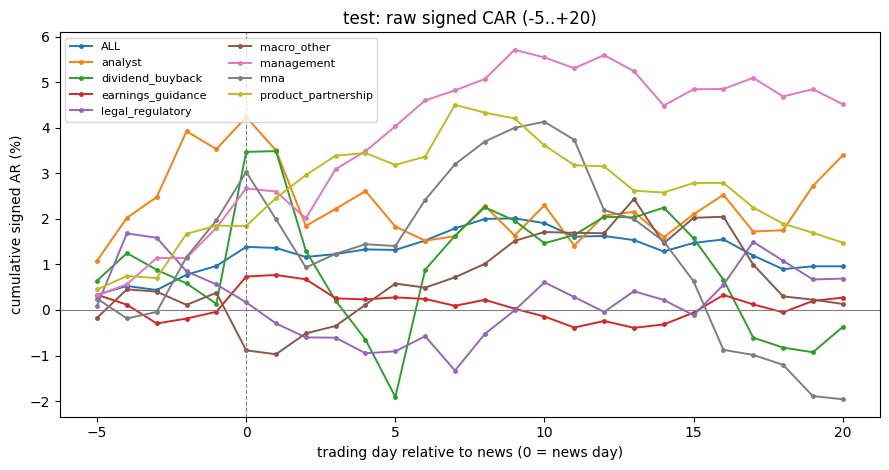

ผลสะสม ณ ปิดวันข่าว 1.384% / วัน +20 0.958% -> ratio 1.45 (เปเปอร์ 2.8)
winsorize 1%:


window,pre,d0,post1,post2
group,,,,
ALL,1.478,0.444,-0.078,-0.393


In [21]:
curves4 = cum_curve(d4).join(cum_curve(d4, "primary_tag"))
curves4.to_csv(P("tables") / "step4_raw_cum_curve.csv")
plot_curves(curves4, f"{MODE}: raw signed CAR (-5..+20)", "fig_step4_raw_cum.png")
c_all = curves4["ALL"]
ratio = c_all.loc[0] / c_all.loc[20] if np.isfinite(c_all.loc[20]) and c_all.loc[20] != 0 else np.nan
print(f"ผลสะสม ณ ปิดวันข่าว {c_all.loc[0]:.3f}% / วัน +20 {c_all.loc[20]:.3f}% -> ratio {ratio:.2f} (เปเปอร์ 2.8)")

# ค่าสุดโต่ง: ดูผลแบบ winsorize 1% ประกอบ
dw = signed(winsorize_cols(directional(ev4), list(CAR_COLS.values()), C.winsor))
print(f"winsorize {C.winsor:.0%}:")
display(wide(summarize(dw, SCOLS)).round(3))

---
# ขั้นตอนที่ 5: เทียบกับ placebo (วันที่ 5) — หัวใจของงาน

benchmark beta เดียวไม่พอดี → มี drift ตกค้างในทุกช่วง · **ข่าวเป็นกลาง** = การเป็นข่าวโดยไม่มีทิศทาง → AR รอบข่าวเหล่านี้ = ค่าฐาน

- ค่าฐาน $b(k, w)$ = CAR เฉลี่ยของข่าวเป็นกลาง แยก 3 กลุ่มขนาด × 4 ช่วง (12 ค่า) รวมทุกประเภทข่าว
- $\text{adjusted} = s \cdot (CAR_w - b_{k,w})$ — หักค่าฐานก่อน แล้วคูณเครื่องหมาย (ใช้ CAR ดิบเท่านั้น)
- ข่าวเป็นกลาง < `min_neutral_per_bucket` ต่อกลุ่ม → ใช้ **วันเงียบ** (หุ้น, วัน ที่ไม่มีเหตุการณ์ในวัน −5..0) แทน
- ห้ามรวมข่าวเป็นกลางในค่าเฉลี่ยกลุ่มมีทิศทาง · กลุ่มขนาดแบ่งวิธีเดียวกับขั้นตอนที่ 4

In [22]:
def quiet_days(ev, tickers, n, seed=0) -> pd.DataFrame:
    days = CAL[(CAL >= pd.Timestamp(C.news_start)) & (CAL <= pd.Timestamp(C.news_end))]
    pos_of = {d: i for i, d in enumerate(CAL)}
    busy = set()
    real = ev[~ev["is_junk"]]
    for t, d in zip(real["ticker"], real["trade_date"]):
        p = pos_of.get(d)
        if p is not None:
            for k in range(6):             # เหตุการณ์วัน p ทำให้วัน p..p+5 ไม่เงียบ
                if p + k < len(CAL):
                    busy.add((t, CAL[p + k]))
    cand = [(t, d) for t in tickers for d in days if (t, d) not in busy]
    rng = np.random.default_rng(seed)
    if len(cand) > n:
        cand = [cand[i] for i in rng.choice(len(cand), n, replace=False)]
    return pd.DataFrame(cand, columns=["ticker", "trade_date"])


def _base_table(df, source):
    rows, daily = [], {}
    for b, g in df.groupby("size_bucket"):
        for w, c in CAR_COLS.items():
            rows.append({"source": source, "size_bucket": int(b), "window": w, "b": g[c].mean(), "n": int(g[c].notna().sum())})
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            daily[int(b)] = np.nan_to_num(np.nanmean(g[AR_COLS].to_numpy(float), 0))
    return pd.DataFrame(rows), daily


def make_baseline(ev_ret, ar, beta, sb, verbose=True):
    neutral = ev_ret[(~ev_ret["is_junk"]) & (ev_ret["direction"] == "neutral")]
    bn, dn = _base_table(neutral, "neutral")
    q = quiet_days(ev_ret, list(ar.columns), C.n_quiet, C.seed)
    bq, dq = pd.DataFrame(), {}
    if len(q):
        q = attach_size(add_returns(q.assign(is_junk=False, direction="quiet", sign=0), ar, beta), sb)
        bq, dq = _base_table(q[q["complete"]], "quiet")
    base = pd.concat([bn, bq], ignore_index=True)
    n_neu = neutral.groupby("size_bucket").size().reindex([0, 1, 2]).fillna(0)
    use = "neutral" if n_neu.min() >= C.min_neutral_per_bucket or bq.empty else "quiet"
    if verbose:
        log(f"[placebo] ข่าวเป็นกลาง/กลุ่มขนาด {n_neu.astype(int).tolist()} "
            f"({len(neutral) / max(1, (~ev_ret['is_junk']).sum()):.0%} ของเหตุการณ์, เปเปอร์ ~22%) "
            f"| วันเงียบ {len(q):,} -> ใช้ค่าฐาน '{use}'")
    chosen = base[base["source"] == use]
    bmap = {(r.size_bucket, r.window): r.b for r in chosen.itertuples()}
    overall = chosen.groupby("window")["b"].mean().to_dict()
    for k in (0, 1, 2):
        for w in WINDOWS:
            v = bmap.get((k, w), np.nan)
            bmap[(k, w)] = v if np.isfinite(v) else float(np.nan_to_num(overall.get(w, 0.0)))
    return base.assign(used=base["source"] == use), use, bmap, (dn if use == "neutral" else dq)


def apply_adjust(ev_ret, bmap):
    ev = ev_ret.copy()
    k = ev["size_bucket"].fillna(1).astype(int)
    for w, c in CAR_COLS.items():
        ev[f"b_{w}"] = np.array([bmap[(kk, w)] for kk in k])
        ev[ADJ_COLS[w]] = ev["sign"] * (ev[c] - ev[f"b_{w}"])
        ev[f"s_{c}"] = ev["sign"] * ev[c]
    is_dir = (~ev["is_junk"]) & ev["direction"].isin(["positive", "negative"])
    for c in list(ADJ_COLS.values()) + list(SCOLS.values()):
        ev.loc[~is_dir, c] = np.nan            # ข่าวเป็นกลางไม่เข้าค่าเฉลี่ยกลุ่มมีทิศทาง
    return ev


def raw_vs_adj(d, by=None):
    return pd.concat([summarize(d, SCOLS, by).assign(kind="raw"), summarize(d, ADJ_COLS, by).assign(kind="adjusted")],
                     ignore_index=True)


def side_by_side(t):
    return pd.concat({k: wide(t[t["kind"] == k]) for k in ["raw", "adjusted"]}, axis=1).round(3)


ev_ret = pd.read_parquet(P("event_returns.parquet"))
base, BASE_USED, BMAP, DAILY = make_baseline(ev_ret, ar, beta, SB)
base.to_parquet(P("baseline.parquet"), index=False)
ev5 = apply_adjust(ev_ret, BMAP)
ev5.to_parquet(P("event_returns_adj.parquet"), index=False)
print("ค่าฐาน (% CAR) — ข่าวเป็นกลาง vs วันเงียบ (เปเปอร์ d0..: เป็นกลาง −0.92/−0.58/−0.34, วันเงียบ −0.74/−0.88/−0.59 เล็ก/กลาง/ใหญ่):")
display(base.pivot_table(index=["source", "size_bucket"], columns="window", values="b")[list(WINDOWS)].mul(100).round(3))

[placebo] ข่าวเป็นกลาง/กลุ่มขนาด [2, 10, 19] (23% ของเหตุการณ์, เปเปอร์ ~22%) | วันเงียบ 2,224 -> ใช้ค่าฐาน 'quiet'


ค่าฐาน (% CAR) — ข่าวเป็นกลาง vs วันเงียบ (เปเปอร์ d0..: เป็นกลาง −0.92/−0.58/−0.34, วันเงียบ −0.74/−0.88/−0.59 เล็ก/กลาง/ใหญ่):


window                 pre     d0  post1  post2
source  size_bucket                            
neutral 0           -2.575  0.134 -0.440  6.611
        1           -0.512 -0.269  0.958 -2.606
        2            2.909  0.565  1.739 -0.968
quiet   0            0.211  0.039 -0.179 -0.900
        1            0.035  0.024 -0.198 -0.238
        2            0.491  0.092 -0.427 -1.973

In [23]:
d5 = directional(ev5)
main5 = pd.concat([raw_vs_adj(d5), raw_vs_adj(d5, "primary_tag")], ignore_index=True)
main5.to_csv(P("tables") / "step5_main_raw_vs_adj.csv", index=False)
print("ตารางหลัก: raw vs adjusted (%)")
t5 = side_by_side(main5)
t5[("", "n")] = wide(main5[main5["kind"] == "adjusted"], "n")["pre"]
display(t5)
print("p-value adjusted:")
display(wide(main5[main5["kind"] == "adjusted"], "p").round(3))

ตารางหลัก: raw vs adjusted (%)


raw                      adjusted                          
window                 pre     d0  post1  post2      pre     d0  post1  post2    n
group                                                                             
ALL                  1.384  0.418 -0.068 -0.358    1.192  0.381  0.110  0.421  103
analyst              4.234  0.705 -2.404  1.562    4.024  0.665 -2.221  2.407    7
dividend_buyback     3.470  3.335 -5.378  1.535    3.072  3.260 -5.034  3.150    3
earnings_guidance    0.733  0.773 -0.457 -0.005    0.579  0.743 -0.314  0.619   39
legal_regulatory     0.166 -0.394 -1.074  1.596    0.587 -0.315 -1.439 -0.109    4
macro_other         -0.886 -1.263  1.466 -0.448   -1.067 -1.296  1.609  0.279   13
management           2.668  0.866  1.363  0.483    2.615  0.854  1.426  0.705   10
mna                  3.029  1.064 -1.625 -3.363    2.708  0.999 -1.299 -2.039    7
product_partnership  1.844 -0.005  1.338 -1.705    1.463 -0.079  1.694 -0.153   20

p-value adjusted:


window,pre,d0,post1,post2
group,,,,
ALL,0.014,0.166,0.814,0.339
analyst,NaN,NaN,NaN,NaN
dividend_buyback,NaN,NaN,NaN,NaN
earnings_guidance,0.487,0.253,0.539,0.389
legal_regulatory,NaN,NaN,NaN,NaN
macro_other,0.555,0.042,0.072,0.764
management,0.026,0.012,0.212,0.721
mna,0.036,0.337,0.002,0.295
product_partnership,0.160,0.810,0.006,0.800


ข่าวดี / ข่าวร้าย (เปเปอร์ post: raw −0.62% / +0.63% -> adjusted 0.00% ทั้งคู่)


raw                      adjusted                     
window      pre     d0  post1  post2      pre     d0  post1  post2
group                                                             
negative -0.668 -0.318  0.639  1.545   -0.354 -0.254  0.316  0.245
positive  2.113  0.680 -0.319 -1.034    1.742  0.607  0.037  0.483

กลุ่มขนาด 0=ใหญ่ 1=ใหญ่กว่า 2=ใหญ่ที่สุด (เปเปอร์: หุ้นเล็กกลับตัวมากกว่าหุ้นใหญ่ 2.4 เท่า ใน raw แล้วหายไป)


raw                      adjusted                     
window    pre     d0  post1  post2      pre     d0  post1  post2
group                                                           
0       3.568  1.671 -0.263 -0.028    3.498  1.657 -0.203  0.272
1       1.546  0.282  0.260  0.211    1.536  0.274  0.320  0.283
2       0.943  0.243 -0.144 -0.609    0.669  0.192  0.094  0.494

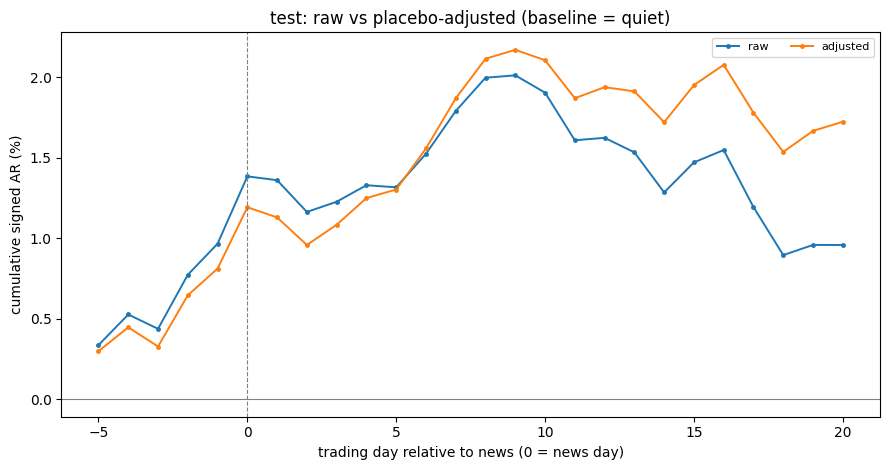

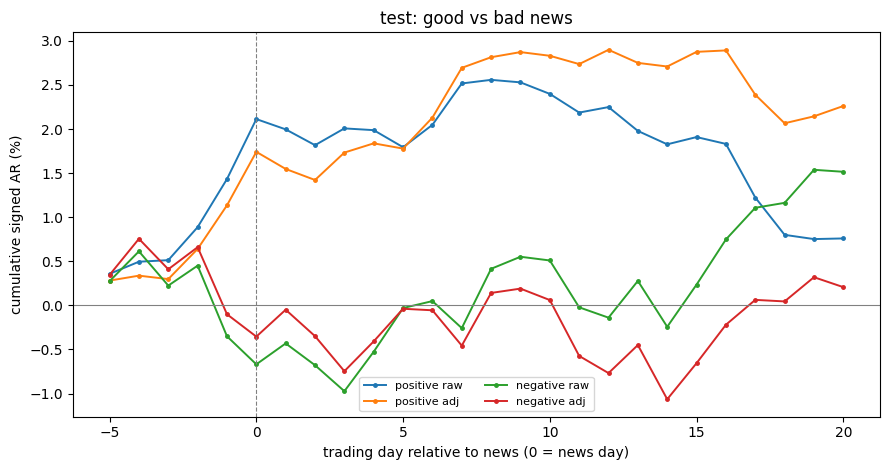

In [24]:
# ทดสอบภาพลวงตา: ข่าวดี/ข่าวร้าย และกลุ่มขนาด — ความต่างแบบ raw ควรหายไปหลัง adjusted
gb5 = raw_vs_adj(d5, "direction")
sz5 = raw_vs_adj(d5, "size_bucket")
gb5.to_csv(P("tables") / "step5_good_vs_bad.csv", index=False)
sz5.to_csv(P("tables") / "step5_by_size.csv", index=False)
print("ข่าวดี / ข่าวร้าย (เปเปอร์ post: raw −0.62% / +0.63% -> adjusted 0.00% ทั้งคู่)")
display(side_by_side(gb5))
print("กลุ่มขนาด 0=ใหญ่ 1=ใหญ่กว่า 2=ใหญ่ที่สุด (เปเปอร์: หุ้นเล็กกลับตัวมากกว่าหุ้นใหญ่ 2.4 เท่า ใน raw แล้วหายไป)")
display(side_by_side(sz5))

c5 = pd.DataFrame({"raw": cum_curve(d5)["ALL"], "adjusted": cum_curve(d5, baseline=DAILY)["ALL"]})
plot_curves(c5, f"{MODE}: raw vs placebo-adjusted (baseline = {BASE_USED})", "fig_step5_raw_vs_adj.png")
gbc = pd.concat({f"{k} {lab}": cum_curve(d5[d5["direction"] == k], baseline=bl)["ALL"]
                 for k in ["positive", "negative"] for lab, bl in [("raw", None), ("adj", DAILY)]}, axis=1)
plot_curves(gbc, f"{MODE}: good vs bad news", "fig_step5_good_vs_bad.png")
pd.concat([c5, gbc], axis=1).to_csv(P("tables") / "step5_cum_curves.csv")

---
# ขั้นตอนที่ 6: ตรวจความทนทาน (วันที่ 6)

**ควรทำ** (ทุก variant ใช้ค่า adjusted)
1. NEW only: `n_new > 0`
2. วันข่าวประเภทเดียว: (หุ้น, วัน) ที่มี 1 ป้าย
3. รายปี 2021 / 2022 / 2023 (ขาขึ้น / ขาลง / ฟื้นตัว)
4. Benjamini-Hochberg FDR 5% ภายในแต่ละ variant (`multipletests(..., "fdr_bh")`)
5. ป้ายที่ 2 โมเดลตรงกัน: ติดป้ายซ้ำ `second_model_n` บทความด้วย `second_model` แล้วสร้างเหตุการณ์จากบทความที่ป้ายหลักตรงกันเท่านั้น
6. bootstrap 5,000 รอบ (โหมด full)

**ทำถ้ามีเวลา**: คุณลักษณะ (`scheduled, quantified, rumor`), benchmark 3 ปัจจัย SPY + GLD + IEF (rolling OLS → ขั้นตอนที่ 4–5 ซ้ำ)

In [25]:
DO_TWO_MODEL = True
DO_3FACTOR = True


def adj_table(d, variant):
    return pd.concat([summarize(d, ADJ_COLS), summarize(d, ADJ_COLS, "primary_tag")], ignore_index=True).assign(variant=variant)


def events_to_adj(ev, ar_, beta_, bmap=None):
    ev = attach_size(add_returns(ev, ar_, beta_), SB)
    ev = ev[ev["ticker"].isin(ar_.columns) & ev["complete"]]
    if bmap is None:
        _, _, bmap, _ = make_baseline(ev, ar_, beta_, SB, verbose=False)
    return apply_adjust(ev, bmap)


ev6 = pd.read_parquet(P("event_returns_adj.parquet"))
d6 = directional(ev6)
tabs = [adj_table(d6, "all"), adj_table(d6[d6["n_new"] > 0], "new_only"), adj_table(d6[d6["n_tags_day"] == 1], "single_tag_day")]
for y, g in d6.groupby(d6["trade_date"].dt.year):
    tabs.append(adj_table(g, f"year_{y}"))
INFO = {}

if DO_TWO_MODEL:
    st6 = pd.read_parquet(P("news_stories.parquet"))
    sample = st6.sample(min(C.second_model_n, len(st6)), random_state=C.seed)
    src = pd.read_parquet(P("news_tagged.parquet"))
    labs2 = label_rows(src[src["row_id"].isin(sample["row_id"])], C.second_model)
    if len(labs2):
        m2 = sample.merge(labs2[["row_id", "primary_tag", "sentiment"]].rename(
            columns={"primary_tag": "tag2", "sentiment": "sent2"}), on="row_id", how="inner")
        agree = m2["primary_tag"] == m2["tag2"].replace(TAG_MERGE)
        INFO = {"n_double_labeled": len(m2), "tag_agreement": round(float(agree.mean()), 3),
                "sentiment_sign_agreement": round(float((np.sign(m2["sentiment"]) == np.sign(m2["sent2"])).mean()), 3)}
        tabs.append(adj_table(directional(events_to_adj(build_events(m2[agree]), ar, beta, BMAP)), "two_model_agree"))

if DO_3FACTOR:
    ar3, beta3 = compute_ar(close, C.factors3)          # ค่าฐานประมาณใหม่ด้วย AR 3 ปัจจัย
    tabs.append(adj_table(directional(events_to_adj(pd.read_parquet(P("events.parquet")), ar3, beta3)),
                          "3factor_" + "+".join(C.factors3)))

rob = pd.concat(tabs, ignore_index=True)
rob["q"] = np.nan
for v, g in rob.groupby("variant"):                    # BH ภายในแต่ละ variant (ไม่รวมแถว ALL)
    idx = g.index[g["group"] != "ALL"]
    rob.loc[idx, "q"] = bh_qvalues(rob.loc[idx, "p"])
rob.to_csv(P("tables") / "step6_robustness.csv", index=False)
print("2 โมเดล:", INFO)
robust_wide = rob.pivot_table(index=["group", "window"], columns="variant", values="mean_pct")
robust_wide.to_csv(P("tables") / "step6_robustness_wide.csv")
print("ตารางความทนทาน (adjusted CAR %, ช่วง post1 และ post2):")
display(robust_wide.loc[(slice(None), ["post1", "post2"]), :].round(3))
print("จำนวนเหตุการณ์ต่อ variant:")
display(rob[rob["group"] == "ALL"].groupby("variant")["n"].max().to_frame().T)

[llm] anthropic/claude-haiku-5.5 | prompt rumor-v1 | cached 206 | todo 100


[llm] เสร็จ 100/100 | fail 0 | cost $0.0513 ($0.000513/แถว) | 22s


2 โมเดล: {'n_double_labeled': 100, 'tag_agreement': 0.78, 'sentiment_sign_agreement': 0.73}
ตารางความทนทาน (adjusted CAR %, ช่วง post1 และ post2):


variant                     3factor_SPY+GLD+IEF    all  new_only  single_tag_day  two_model_agree  year_2023
group               window                                                                                  
ALL                 post1                 0.109  0.110     0.106           0.086           -0.968      0.110
                    post2                 0.258  0.421     0.406           0.574            0.783      0.421
analyst             post1                -2.351 -2.221    -2.221          -2.221           -2.870     -2.221
                    post2                 1.867  2.407     2.407           2.407            3.209      2.407
dividend_buyback    post1                -4.483 -5.034    -5.034          -5.034           -5.034     -5.034
                    post2                 3.491  3.150     3.150           3.150            3.150      3.150
earnings_guidance   post1                -0.070 -0.314    -0.314          -0.368           -1.279     -0.314
                    post2                 0.504  0.619     0.619           0.557           -0.162      0.619
legal_regulatory    post1                -0.724 -1.439    -2.083          -0.137           -1.439     -1.439
                    post2                -0.034 -0.109    -0.781           2.613           -0.109     -0.109
macro_other         post1                 1.444  1.609     1.609           1.742           -0.158      1.609
                    post2                 0.158  0.279     0.279           0.777           -1.005      0.279
management          post1                 1.375  1.426     1.426           1.426            1.372      1.426
                    post2                 0.586  0.705     0.705           0.705            4.189      0.705
mna                 post1                -2.285 -1.299    -1.299          -1.299           -1.799     -1.299
                    post2                -1.790 -2.039    -2.039          -2.039           -0.523     -2.039
product_partnership post1                 1.512  1.694     1.694           1.682            2.619      1.694
                    post2                -0.590 -0.153    -0.153          -0.042            1.752     -0.153

จำนวนเหตุการณ์ต่อ variant:


variant,3factor_SPY+GLD+IEF,all,new_only,single_tag_day,two_model_agree,year_2023
n,103,103,102,95,51,103


In [26]:
# q-value (BH) และตาราง drift ฉบับสุดท้าย: *** q<0.01, ** q<0.05, * q<0.10
print("q-value (variant = all):")
display(wide(rob[rob["variant"] == "all"], "q").round(3))
main6 = rob[rob["variant"] == "all"].copy()
star = np.select([main6["q"] < 0.01, main6["q"] < 0.05, main6["q"] < 0.10], ["***", "**", "*"], "")
main6["cell"] = main6["mean_pct"].map(lambda v: f"{v:+.2f}" if np.isfinite(v) else "") + star
drift = main6.pivot(index="group", columns="window", values="cell")[list(WINDOWS)]
drift["n"] = main6.groupby("group")["n"].max()
drift.index = [TAGS.get(i, i) for i in drift.index]
drift.to_csv(P("tables") / "step6_final_drift_table.csv")
print("ตาราง drift ฉบับสุดท้าย (adjusted, %):")
display(drift)

# คุณลักษณะ และขนาดหุ้น
attrs = pd.concat([summarize(d6, ADJ_COLS, a).assign(attribute=a) for a in ["scheduled", "quantified", "rumor"]], ignore_index=True)
attrs.to_csv(P("tables") / "step6_attributes.csv", index=False)
print("คุณลักษณะ (เปเปอร์: มีกำหนดการไหลต่อ +0.08%, ไม่มีตัวเลขกลับตัว −0.12%):")
display(pd.concat({a: wide(g) for a, g in attrs.groupby("attribute")}).round(3))
size6 = summarize(d6, ADJ_COLS, "size_bucket")
size6.to_csv(P("tables") / "step6_by_size.csv", index=False)
display(wide(size6).round(3))

q-value (variant = all):


window,pre,d0,post1,post2
group,,,,
ALL,NaN,NaN,NaN,NaN
analyst,NaN,NaN,NaN,NaN
dividend_buyback,NaN,NaN,NaN,NaN
earnings_guidance,0.694,0.507,0.694,0.599
legal_regulatory,NaN,NaN,NaN,NaN
macro_other,0.694,0.140,0.205,0.810
management,0.130,0.080,0.470,0.810
mna,0.140,0.562,0.040,0.537
product_partnership,0.399,0.810,0.060,0.810


ตาราง drift ฉบับสุดท้าย (adjusted, %):


window,pre,d0,post1,post2,n
ALL,+1.19,+0.38,+0.11,+0.42,103
นักวิเคราะห์,+4.02,+0.67,-2.22,+2.41,7
ปันผล/ซื้อหุ้นคืน,+3.07,+3.26,-5.03,+3.15,3
ผลประกอบการ + guidance,+0.58,+0.74,-0.31,+0.62,39
คดีความ/กฎระเบียบ,+0.59,-0.32,-1.44,-0.11,4
มหภาค/อื่น ๆ,-1.07,-1.30,+1.61,+0.28,13
ผู้บริหาร,+2.62,+0.85*,+1.43,+0.70,10
M&A,+2.71,+1.00,-1.30**,-2.04,7
เปิดตัวสินค้า + พันธมิตร,+1.46,-0.08,+1.69*,-0.15,20


คุณลักษณะ (เปเปอร์: มีกำหนดการไหลต่อ +0.08%, ไม่มีตัวเลขกลับตัว −0.12%):


window              pre     d0  post1  post2
           group                            
quantified False  2.609  0.602  0.736 -0.125
           True   0.807  0.321 -0.060  0.569
rumor      False  1.103  0.365  0.091  0.458
           True   2.641  0.646  0.423 -0.174
scheduled  False  1.142  0.158  0.587  0.268
           True   1.265  0.706 -0.582  0.643

window,pre,d0,post1,post2
group,,,,
0,3.498,1.657,-0.203,0.272
1,1.536,0.274,0.320,0.283
2,0.669,0.192,0.094,0.494


### เทียบกับเปเปอร์
ตัวเลขของเปเปอร์ (adjusted drift หลังข่าว) ใช้ 17 ป้าย — ป้ายที่เรารวม (ผลประกอบการ + guidance, เปิดตัวสินค้า + พันธมิตร) ใช้ค่าเฉลี่ยคร่าว ๆ ของเปเปอร์เป็นตัวอ้างอิงเท่านั้น

In [27]:
PAPER = {  # adjusted drift หลังข่าวจากเปเปอร์ (%)
    "dividend_buyback": 0.35, "earnings_guidance": (0.22 + 0.13) / 2, "analyst": 0.10,
    "macro_other": -0.34, "product_partnership": -0.18, "management": -0.18, "legal_regulatory": -0.08,
}
ours = main6.pivot(index="group", columns="window", values="mean_pct")
ours["post_1_20"] = ours["post1"] + ours["post2"]
cmp_ = pd.DataFrame({"paper_post": pd.Series(PAPER), "ours_post1": ours["post1"], "ours_post2": ours["post2"],
                     "ours_post_1_20": ours["post_1_20"]}).round(3)
cmp_["same_sign"] = (np.sign(cmp_["paper_post"]) == np.sign(cmp_["ours_post_1_20"])).where(cmp_["paper_post"].notna())
cmp_.index = [TAGS.get(i, i) for i in cmp_.index]
display(cmp_)
summary = {
    "mode": MODE, "universe": len(universe) if "universe" in dir() else None,
    "articles_tagged": len(pd.read_parquet(P("news_tagged.parquet"))),
    "events_measured": len(ev6), "directional": len(d6),
    "follow_up_share": round(1 - pd.read_parquet(P("news_stories.parquet"))["is_new"].mean(), 3),
    "neutral_share": round(float((ev6.loc[~ev6["is_junk"], "direction"] == "neutral").mean()), 3),
    "ratio_d0_to_d20_raw": round(float(ratio), 2) if np.isfinite(ratio) else None,
    "baseline_used": BASE_USED, **INFO,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
summary

,paper_post,ours_post1,ours_post2,ours_post_1_20,same_sign
ALL,NaN,0.110,0.421,0.531,False
นักวิเคราะห์,0.100,-2.221,2.407,0.187,True
ปันผล/ซื้อหุ้นคืน,0.350,-5.034,3.150,-1.884,False
ผลประกอบการ + guidance,0.175,-0.314,0.619,0.305,True
คดีความ/กฎระเบียบ,-0.080,-1.439,-0.109,-1.548,True
มหภาค/อื่น ๆ,-0.340,1.609,0.279,1.889,False
ผู้บริหาร,-0.180,1.426,0.705,2.131,False
M&A,NaN,-1.299,-2.039,-3.338,False
เปิดตัวสินค้า + พันธมิตร,-0.180,1.694,-0.153,1.541,False


{'mode': 'test',
 'universe': 135,
 'articles_tagged': 1106,
 'events_measured': 135,
 'directional': 103,
 'follow_up_share': np.float64(0.017),
 'neutral_share': 0.23,
 'ratio_d0_to_d20_raw': 1.45,
 'baseline_used': 'quiet',
 'n_double_labeled': 100,
 'tag_agreement': 0.78,
 'sentiment_sign_agreement': 0.73}

---
## ข้อจำกัด (เขียนในรายงาน)
- **Look-ahead**: LLM ติดป้ายย้อนหลังและอาจรู้ผลในอนาคต (prompt สั่งให้ตัดสินจากเนื้อข่าวเท่านั้น) ต่างจากเปเปอร์ที่สร้าง sentiment วันต่อวัน
- **Survivorship bias**: ใช้รายชื่อ S&P 500 ปัจจุบัน + ราคา yfinance → ไม่มีบริษัทที่หลุดจากดัชนี
- **หุ้นใหญ่เท่านั้น**: drift และกลยุทธ์ในเปเปอร์ชัดที่สุดในหุ้นเล็ก ซึ่งไม่อยู่ในงานนี้
- **ขนาดข้อมูล**: เล็กกว่าเปเปอร์หลายสิบเท่า และใช้ป้ายน้อยกว่า (8 + ขยะ 2 vs 17)
- **เวลาใน FNSPID**: ข่าวส่วนใหญ่มีแค่วันที่ (00:00) → ใช้กฎ 16:00 ไม่ได้ ข่าวหลังปิดตลาดอาจถูกนับเป็นวันก่อนหน้า 1 วัน (ช่วง pre รวมวัน 0 จึงยังครอบคลุม)
- **FNSPID ไม่ครบ**: ถ้าไฟล์ `nasdaq_exteral_data.csv` ยังดาวน์โหลดไม่ครบ หุ้นท้ายตัวอักษร (หลัง `last_symbol` ใน `fnspid_sp500_2021_2023.json`) ถูกตัดออกจาก universe

## งานขยายรอบถัดไป
- เพิ่มหุ้นเล็กและกลางจาก Nasdaq หรือ S&P 600 ราว 100 ตัว · benchmark 3–4 ปัจจัย (GLD, IEF, IWM)
- วิเคราะห์ข่าวลือแบบเต็ม, ความผันผวน และพอร์ตจำลองที่มี "short หุ้นที่เป็นข่าวทุกตัว" เป็นตัวเทียบ